# Coursework 1
**Replace CID in the file name with your CID**

# Outline


- [Task 1](#task-1): Multi-class classification with Decision Trees and Random Forests <a name="index-task-1"></a>
  - [(1.1)](#task-11) <a name="index-task-11"></a>
  - [(1.2)](#task-12) <a name="index-task-12"></a>
  - [(1.3)](#task-13) <a name="index-task-13"></a>
  - [(1.4)](#task-14) <a name="index-task-14"></a>
- [Task 2](#task-2): Binary classification with the Huberised Support Vector Machine <a name="index-task-2"></a>
  - [(2.1)](#task-21) <a name="index-task-21"></a>
  - [(2.2)](#task-22)  <a name="index-task-22"></a>
- [Task 3](#task-3): Regression with the Multi-Layer Perceptron <a name="index-task-3"></a>
  - [(3.1)](#task-31) <a name="index-task-31"></a>
  - [(3.2)](#task-32)  <a name="index-task-32"></a>



---



<a name="task-1"></a>

# Task 1: Multi-class classification with Decision Trees and Random Forests  [(index)](#index-task-1)

In [214]:
# we first import packages and libraries needed
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from collections import defaultdict
from tqdm import tqdm


# We set a global configuration for matplotlib to obtain well-readable plots
SMALL_SIZE = 12
MEDIUM_SIZE = 16
BIGGER_SIZE = 20

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=BIGGER_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title

# fixing random generator for reproducibility
rng = np.random.default_rng(0)

<a name="task-11"></a>

## (1.1) Comparison between decision trees and K-NN[(index)](#index-task-11)

First I uploaded the dataset

In [215]:
airfield_stats_test = pd.read_csv('airfield_statistics_test.csv')
airfield_stats_train = pd.read_csv('airfield_statistics_train.csv')

X_train_origin = airfield_stats_train.iloc[:, :6].values  
y_train_origin = airfield_stats_train.iloc[:, 6].values

X_train = X_train_origin.copy()
y_train = y_train_origin.copy()

X_test_origin = airfield_stats_test.iloc[:, :6].values  
y_test_origin = airfield_stats_test.iloc[:, 6].values  

X_test = X_test_origin.copy()
y_test = y_test_origin.copy()

cat_columns_dict = {i: False for i in range(X_train.shape[1])} 

feature_names = airfield_stats_train.columns[:6].tolist()  


In [216]:
airfield_stats_test.tail()

,Days of airfrost,Precipitation,Sunshine hours,Humidity (%),Wind Speed,Aircraft total movements,Weather and flight condition category,Runway surface minimal temperature,Runway surface maximal temperature
240,0,22.5,213.7,58.9,2.3,1285,1,12.3,22.5
241,0,25.9,171.7,56.6,2.8,1413,0,7.6,16.0
242,3,68.7,53.7,73.7,4.3,1275,3,3.8,9.4
243,0,116.8,112.9,71.3,4.2,1273,2,10.2,18.1
244,0,41.0,192.6,58.4,3.0,1342,1,12.9,21.5


Part 1: Build a decision tree

In this section, I built a decision tree. I used the code in Decision trees + Random Forest and made some adaptations.

In this section, we have to use Gini index to calculate the loss of each splitting step. Our goal is to predict for each data point $\boldsymbol x = (x_1,\ldots,x_p)$ a label $y \in \mathcal{C}_q=\{c_1,\ldots,c_Q\}$ where we have in total $Q$ classes.

Recall that each split $(j,s)$ split the space of feature $x_j$ into two regions $R_1(j,s)$ and $R_2(j,s)$.

**If the feature is a continuous variable**, the $s$ is used as a threshold such that samples with feature value less than $s$ are assigned to the left, and vice versa. **If the feature is a categorical variable**, the $s$ is used as a predicate such that samples with feature value equals to $s$ are assigned to left, and vice versa.

For a region $R_\alpha$ and a class $c_q$, we define the probability of being in that region and belonging to that class by
$$  \pi_q(R_{\alpha}) = \frac{\sum_{i=1}^N I\big( \boldsymbol x^{(i)} \in R_{\alpha} \land y^{(i)} \in c_q \big)}{\sum_{i=1}^N I(\boldsymbol x^{(i)} \in R_{\alpha})}$$
and we define the $Q\times 1$ vector $\boldsymbol \pi(R_{\alpha})$ whose $q$-th entry is $\pi_q(R_{\alpha})$.

For a general $\boldsymbol p = (p_1,\ldots,p_Q)^\top$, the Gini index $\text{GI}(\boldsymbol p)$ is defined as: $\text{GI}(\boldsymbol p) = 1 - \sum_{i=1}^Q p_i^2 $. To determine the best $j$ and $s$ at each split node, we may use _GINI-index_ to search for $j$ and $s$ that minimizes the weighted sum of _GINI-index_ of the left side samples and right side samples:
  
  $$\text{GI}(\boldsymbol \pi; j, s) = p_{R_1} \text{GI}(\boldsymbol \pi(R_1); j, s) + p_{R_2} \text{GI}(\boldsymbol \pi(R_2); j, s)$$

where $p_{R_1}$ and $p_{R_2}$ are, respectively, the fraction of the number of samples on the left and on the right and $R_1$ and $R_1$ are determined by $(j,s)$.

In [217]:
def gini_index(y):
    """
    Arguments:
        y: vector of training labels, of shape (N,).
    Returns:
        (float): the GINI-index for the labels in a given region.
    """

    # Count occurrences of each unique label in y
    unique_labels, counts = np.unique(y, return_counts=True)

    # Compute probabilities for each label
    p = counts / len(y)

    # Compute the sum of squared probabilities
    sum_p_squared = np.sum(p**2)

    # Return GINI-Index
    return 1 - sum_p_squared


For each column, we will decide the threshold value for splitting. I iterated across all values for each column and find the best splitting threshold: gini_split_value. 
Then, I would decide the specific column as the splitting criterion for this step by comparing the gini values across each column: gini_split.

In [218]:
def split_samples(X, y, column, value, categorical):
    """
    Return the split of data whose column-th feature:
      1. equals value, in case `column` is categorical, or
      2. less than value, in case `column` is not categorical (i.e. numerical)

    Arguments:
        X: training features, of shape (N, p).
        y: vector of training labels, of shape (N,).
        column: the column of the feature for splitting.
        value: splitting threshold  the samples
        categorical: boolean value indicating whether column is a categorical variable or numerical.
    Returns:
        tuple(np.array, np.array, np.array): tuple of the left split data (X_l, y_l).
        tuple(np.array, np.array, np.array): tuple of the right split data (X_l, y_l)
    """

    if categorical:
        left_mask =(X[:, column] == value)
    else:
        left_mask = (X[:, column] < value)

    # Using the binary masks `left_mask`, we split X, y, and sample_weights.
    X_l, y_l = X[left_mask, :], y[left_mask] # <- SOLUTION
    X_r, y_r = X[~left_mask, :], y[~left_mask] # <- SOLUTION

    return (X_l, y_l), (X_r, y_r)

def gini_split_value(X, y, column, categorical):
    """
    Calculate the GINI-index based on `column` with the split that minimizes the GINI-index.
    Arguments:
        X: training features, of shape (N, p).
        y: vector of training labels, of shape (N,).
        column: the column index of the feature for calculating. 0 <= column < p
        categorical: boolean value indicating whether column is a categorical variable or numerical.
    Returns:
        (float, float): the resulted GINI-index and the corresponding value used in splitting.
    """

    unique_vals = np.unique(X[:, column])

    assert len(unique_vals) > 1, f"There must be more than one distinct feature value. Column: {column}."

    gini_index_val, threshold = np.inf, None

    # iterate over all unique values of the i-th feature
    for value in unique_vals:
        # Split the samples into left and right subsets based on the current value
        (X_l, y_l), (X_r, y_r) = split_samples(X, y, column, value, categorical) ## <-- SOLUTION

        # check if one of the subsets is empty (invalid split)
        if len(y_l) == 0 or len(y_r) == 0:
            continue

        # calculate the proportion of samples on the left and right sides
        p_left = len(y_l)/(len(y_l)+len(y_r))
        p_right = len(y_r)/(len(y_l)+len(y_r))

        # compute the GINI index for the left and right subsets
        new_cost = p_left * gini_index(y_l) + p_right * gini_index(y_r) ## <-- SOLUTION

        # update the minimum GINI index and the threshold if this split is better
        if new_cost < gini_index_val:
              gini_index_val, threshold = new_cost, value

    return gini_index_val, threshold

def gini_split(X, y, cat_columns_dict):
    """
    Choose the best feature to split according to criterion.
    Args:
        X: training features, of shape (N, p).
        y: vector of training labels, of shape (N,).
        cat_columns_dict: a dictionary mapping column indices to whether the column is categorical or numerical variable.
    Returns:
        (float, int, float): the minimal Gini index found, the best feature index and value used in splitting.
        If the feature index is None, then no valid split for the current Node.
    """

    # Initialize `split_column` to None, so if None returned this means there is no valid split at the current node.
    min_gini_index = np.inf
    split_column = None
    split_val = np.nan

    for column, categorical in cat_columns_dict.items():
        # skip column if samples are not separable by that column.
        if len(np.unique(X[:, column])) < 2:
            continue
        gini_index, current_split_val = gini_split_value(X, y, column, categorical)  ## <-- SOLUTION


        if gini_index < min_gini_index: ## <-- SOLUTION
            # Keep track with:

            # 1. the current minimum gini-index value,
            min_gini_index = gini_index ## <-- SOLUTION

            # 2. corresponding column,
            split_column = column ## <-- SOLUTION

            # 3. corresponding split threshold.
            split_val = current_split_val ## <-- SOLUTION

    return min_gini_index, split_column, split_val



After reaching the node, the tree decides the lable with democracy :-). The tree classfies the node my majority vote function.

Then, I'm able to build the decision tree

Finally, I can build the decision tree by using `choose_best_feature` to find the best feature to split the `X`, and `split_dataset` to get sub-trees.

In [219]:
def majority_vote(y):
    """
    Return the label which appears the most in y.
    Args:
        y: vector of training labels, of shape (N,).
    Returns:
        (int): the majority label
    """
    # Find unique labels and their counts
    labels, counts = np.unique(y, return_counts=True)

    # Identify the label with the maximum count
    majority_label = labels[np.argmax(counts)]

    return majority_label

def build_tree(X, y, cat_columns_dict, feature_names, depth, max_depth=10, min_samples_leaf=12):
    """Build the decision tree according to the data.
    Args:
        X: (np.array) training features, of shape (N, p).
        y: (np.array) vector of training labels, of shape (N,).
        cat_columns_dict: a dictionary mapping column indices to whether the column is categorical or numerical variable.
        feature_names (list): record the name of features in X in the original dataset.
        depth (int): current depth for this node.
        max_depth (int): maximum depth of the tree.
        min_samples_leaf (int): minimum number of samples in a leaf node.
    Returns:
        (dict): a dict denoting the decision tree (binary-tree). Each parent node has seven attributes:
          1. 'feature_name': The column name of the split.
          2. 'feature_index': The column index of the split.
          3. 'value': The value used for the split.
          4. 'categorical': indicator for categorical/numerical variables.
          5. 'majority_label': For leaf nodes, this stores the dominant label. Otherwise, it is None.
          6. 'left': The left sub-tree with the same structure.
          7. 'right' The right sub-tree with the same structure.
    """
    # include a clause for the cases where (i) no feature, (ii) all labels are the same,
    # (iii) depth exceeded, or (iv) X is too small
    if len(np.unique(y))==1 or depth>max_depth or len(X)<=min_samples_leaf:
        return {'majority_label': majority_vote(y)}

    GI, split_index, split_val = gini_split(X, y, cat_columns_dict)  ## <-- SOLUTION

    # If no valid split at this node, use majority vote.
    if split_index is None:
        return {'majority_label': majority_vote(y)}

    categorical = cat_columns_dict[split_index]

    # Split samples (X, y, sample_weights) given column, split-value, and categorical flag.
    (X_l, y_l), (X_r, y_r) = split_samples(X, y, split_index, split_val, categorical) ## <-- SOLUTION
    return {
        'feature_name': feature_names[split_index],
        'feature_index': split_index,
        'value': split_val,
        'categorical': categorical,
        'majority_label': None,
        'left': build_tree(X_l, y_l, cat_columns_dict, feature_names, depth + 1, max_depth, min_samples_leaf),
        'right': build_tree(X_r, y_r, cat_columns_dict, feature_names, depth + 1, max_depth, min_samples_leaf)
    }

Then, I define a wrapper to call the tree function as train.

In [220]:
def train(X, y,  cat_columns_dict, max_depth=10):
    """
    Build the decision tree according to the training data.
    Args:
        X: (pd.Dataframe) training features, of shape (N, p). Each X[i] is a training sample.
        y: (pd.Series) vector of training labels, of shape (N,). y[i] is the label for X[i], and each y[i] is
        an integer in the range 0 <= y[i] <= C. Here C = 1.
        cat_columns_dict: a dictionary mapping column indices to whether the column is categorical or numerical variable.
        sample_weights: weights for each samples, of shape (N,).
    """

    feature_names = X.columns.tolist()
    X = X.to_numpy()
    y = y.to_numpy()
    return build_tree(X, y, cat_columns_dict, feature_names, depth=1, max_depth=max_depth)

After fitting the training values to the decision tree, I am able to use the tree to make prediction. Here defining functions to classify and predict the new input. 

In [221]:
# EDIT THIS FUNCTION
def classify(tree, x):
    """
    Classify a single sample with the fitted decision tree.
    Args:
        x: ((pd.Dataframe) a single sample features, of shape (p,).
    Returns:
        (int): predicted testing sample label.
    """
    if tree['majority_label'] is not None:
        return tree['majority_label']

    elif tree['categorical']:
        if x[tree['feature_index']] == tree['value']:
            # go to left branch
            return classify(tree['left'], x)
        else:
            # go to right branch
            return classify(tree['right'], x)

    else:

        if x[tree['feature_index']] < tree['value']: # <- SOLUTION
            # go to left branch
            return classify(tree['left'], x)  # <- SOLUTION
        else:
            # go to right branch
            return classify(tree['right'], x)  # <- SOLUTION
        
def predict(tree, X):
    """
    Predict classification results for X.
    Args:
        X: (pd.Dataframe) testing sample features, of shape (N, p).
    Returns:
        (np.array): predicted testing sample labels, of shape (N,).
    """
    if len(X.shape) == 1:
        return classify(tree, X)
    else:
        return np.array([classify(tree, x) for x in X])
    
## EDIT THIS FUNCTION
def tree_score(tree, X_test, y_test):
    y_pred = predict(tree, X_test) ## <-- SOLUTION
    return np.mean(y_pred==y_test)

In [222]:
feature_names = airfield_stats_train.columns[:6].tolist()

max_depth = 10
min_samples_leaf = 12

Define a standardise function

In [223]:
def standardise(X, X_train_=None):
    """Standardise features.

    Parameters:
        X (np.array): Feature matrix.
        X_train_ (np.array): An optional feature matrix to compute the statistics
            from before applying it to X. If None, just use X to compute the statistics.

    Returns:
        X_std (np.array): Standardised feature matrix
    """
    if X_train_ is None:
        X_train_ = X

    mu = np.mean(X_train_, axis=0, keepdims=True) ## <-- SOLUTION
    sigma = np.std(X_train_, axis=0, keepdims=True) ## <-- SOLUTION
    X_std = (X - mu) / sigma ## <-- SOLUTION
    return X_std

First, I calculate the accuracy for the non-standardised version

In [224]:
#Non standardized section
tree =  train(pd.DataFrame(X_train), pd.DataFrame(y_train), cat_columns_dict)
tree_train = tree_score(tree, X_train, y_train)
print('Training accuracy:', tree_score(tree, X_train, y_train))
tree_test = tree_score(tree, X_test, y_test)
print('Test accuracy:', tree_score(tree, X_test, y_test))
print('Difference between training set and test',abs(tree_score(tree, X_train, y_train)-tree_score(tree, X_test, y_test)) )

Training accuracy: 0.9281961471103327
Test accuracy: 0.8530612244897959
Difference between training set and test 0.07513492262053678


Then I standardised the dataset and calculate the accuracy

In [225]:
X_train_std=standardise(X_train)
X_test_std=standardise(X_test)
tree = build_tree(X_train_std, y_train, cat_columns_dict, feature_names, depth=0, max_depth=max_depth, min_samples_leaf=min_samples_leaf)
tree_train_std = tree_score(tree, X_train_std, y_train)
print('Training accuracy:', tree_score(tree, X_train_std, y_train))
tree_test_std = tree_score(tree, X_test_std, y_test)
print('Test accuracy:', tree_score(tree, X_test_std, y_test))
print('Difference between training set and test',abs(tree_score(tree, X_train, y_train)-tree_score(tree, X_test, y_test)) )

Training accuracy: 0.9281961471103327
Test accuracy: 0.8530612244897959
Difference between training set and test 0.01020765574180632


Part 2: KNN classification

In this section, I used the code from K-Neatest Neighbours and made some slight adaptations. 

In KNN classification, I use Euclidean distance to calculate the disparity between two data points, defined as
$$
d(\boldsymbol x^{(i)}, \boldsymbol x^{(j)}) = \sqrt{\sum_{m=1}^p{(x^{(i)}_m-x^{(j)}_m)^2}} \, ,
$$
where $\boldsymbol x^{(i)}$ and $\boldsymbol x^{(j)}$ are the two points in our $p$-dimensional Euclidean space.

In [226]:
def euclidean_distance(x_i, x_j):

    '''
    Argument:
    x_i: vector with shape (p,)
    x_j: vector with shape (p,) or matrix with shape (n, p)

    Returns:
    d: distance between x_i and x_j (if both vectors), or between x_i and each row of x_j (if x_j is matrix)
    '''

    assert x_i.shape == x_j.shape or x_j.shape[1] == x_i.shape[0]

    return np.sqrt(np.sum((x_i-x_j)**2, axis=1)) ## <-- SOLUTION

Then I define the function for K Nearest Neighbours

In [227]:


def k_neighbours(X_train, X_test, k=5, return_distance=False):
  """
  This function finds the k nearest neighbours in X_train for each point in X_test .

  Argument:
  X_train: training data
  X_test: test data
  k: number of nearest neighbours
  return_distance: if True, return distances too

  Returns:
  np.array(neigh_ind): array of indices of k nearest neighbours

  """

  n_neighbours = k
  dist = []
  neigh_ind = []

  # compute distance from each point x_test in X_test to all points in X_train (hint: use python's list comprehension)
  point_dist = [euclidean_distance(x_test, X_train) for x_test in X_test] ## <-- SOLUTION

  # determine which k training points are closest to each test point
  for row in point_dist:
      enum_neigh = enumerate(row)
      sorted_neigh = sorted(enum_neigh, key=lambda x: x[1])[:k]

      ind_list = [tup[0] for tup in sorted_neigh]
      dist_list = [tup[1] for tup in sorted_neigh]

      dist.append(dist_list)
      neigh_ind.append(ind_list)

  # return distances together with indices of k nearest neighbours
  if return_distance:
      return np.array(dist), np.array(neigh_ind)

  return np.array(neigh_ind)


After building a model of KNN, I use the model to predict the outcome>

In [228]:

def predict(X_train, y_train, X_test, k=5):
  """
  This function predicts labels of test data given training data and labels.

  Argument:
  X_train: training data
  y_train: training labels
  X_test: test data
  k: number of nearest neighbours

  Returns:
  y_pred: predicted labels for X_test

  """
  # each of the k neighbours contributes equally to the classification of any data point in X_test
  neighbours = k_neighbours(X_train, X_test, k=k)
  # count number of occurences of label with np.bincount and choose the label that has most with np.argmax (hint: use python's list comprehension)
  y_pred = np.array([np.argmax(np.bincount(y_train[neighbour])) for neighbour in neighbours]) ## <-- SOLUTION

  return y_pred

def score(X_train, y_train, X_test, y_test, k=5):

  y_pred = predict(X_train, y_train, X_test, k=k) ## <-- SOLUTION

  return float(sum(y_pred==y_test))/ float(len(y_test))

First, I use the non-standardised version to train the model and calculate the accuracy.

In [229]:
#Non-standardised version
k = 25
print('Training set mean accuracy:', score(X_train, y_train, X_train, y_train, k=k))
print('Test set mean accuracy:', score(X_train, y_train, X_test, y_test, k=k))

Training set mean accuracy: 0.6112084063047285
Test set mean accuracy: 0.6040816326530613


Then, I standardised the dataset and calculate the accuracy

In [230]:
#Standardised version
k = 25
print('Training set mean accuracy:', score(X_train_std, y_train, X_train_std, y_train, k=k))
print('Test set mean accuracy:', score(X_train_std, y_train, X_test_std, y_test, k=k))

Training set mean accuracy: 0.7968476357267951
Test set mean accuracy: 0.8081632653061225


Here, I combine the results from both sets and compare the performances. I used DataFrame to build a clearer view for comparison. 

Original dataset accuracy comparison:

In [231]:
DT_original = {"Mean Accuracy": ["Training", "Testing"], "Decision Tree":[tree_train, tree_test], "KNN":[score(X_train, y_train, X_train, y_train, k=k), score(X_train, y_train, X_test, y_test, k=k)]}
print(pd.DataFrame(DT_original))

  Mean Accuracy  Decision Tree       KNN
0      Training       0.928196  0.611208
1       Testing       0.853061  0.604082


Standardised dataset accuracy comparison:

In [232]:
DT_std = {"Mean Accuracy": ["Training", "Testing"], "Decision Tree":[tree_train_std, tree_test_std], "KNN":[score(X_train_std, y_train, X_train_std, y_train, k=k), score(X_train_std, y_train, X_test_std, y_test, k=k)]}
print(pd.DataFrame(DT_std))

  Mean Accuracy  Decision Tree       KNN
0      Training       0.928196  0.796848
1       Testing       0.853061  0.808163


As a result, I am able to conclude that the standardization would not affect the accuracy of decision trees too much. The decision tree use a binary model to split the values, so a change in scale of dataset would not affect the accuracy too much. In comparison, KNN model relies on the measurement of distance. Standardasation would exclude the effect of some dominant values or outliers in the measurement, producing a more reasonble distance therefore a more accurate result. 

<a name="task-12"></a>

## (1.2) Decision tree for soft classification [(index)](#index-task-12)

In the soft tree classification, we no longer use the majority vote. The soft classification produces a vector of possibilities of each class. I modified the build_tree function to build_tree soft. Instead of producing a definite result, the soft tree produces a vector of possibility for each class. 

In [233]:
def build_tree_soft(X, y, cat_columns_dict, feature_names, depth, max_depth=10, min_samples_leaf=12):
    """Build the soft decision tree according to the data.
    Args:
        X: (np.array) training features, of shape (N, p).
        y: (np.array) vector of training labels, of shape (N,).
        cat_columns_dict: a dictionary mapping column indices to whether the column is categorical or numerical variable.
        feature_names (list): record the name of features in X in the original dataset.
        depth (int): current depth for this node.
        max_depth (int): maximum depth of the tree.
        min_samples_leaf (int): minimum number of samples in a leaf node.
    Returns:
        (dict): a dict denoting the decision tree (binary-tree). Each parent node has seven attributes:
          1. 'feature_name': The column name of the split.
          2. 'feature_index': The column index of the split.
          3. 'value': The value used for the split.
          4. 'categorical': indicator for categorical/numerical variables.
          5. 'class_probs': For leaf nodes, this stores the soft classifications by probabilities. Otherwise, it is None.
          6. 'left': The left sub-tree with the same structure.
          7. 'right' The right sub-tree with the same structure.
    """
    # include a clause for the cases where (i) no feature, (ii) all labels are the same,
    # (iii) depth exceeded, or (iv) X is too small
    if len(np.unique(y)) == 1 or depth > max_depth or len(X) <= min_samples_leaf:
        # Return soft classification probabilities (4-class output)
        class_probs = np.zeros(4)
        for label in np.unique(y):
            class_probs[label] = np.sum(y == label) / len(y)
        return {'class_probs': class_probs}

    GI, split_index, split_val = gini_split(X, y, cat_columns_dict)

    # If no valid split at this node, return the soft classfication reult
    if split_index is None:
        class_probs = np.bincount(y) / len(y)
        return {'class_probs': class_probs}

    categorical = cat_columns_dict[split_index]

    # Split samples (X, y, sample_weights) given column, split-value, and categorical flag.
    (X_l, y_l), (X_r, y_r) = split_samples(X, y, split_index, split_val, categorical)
    
    return {
        'feature_name': feature_names[split_index],
        'feature_index': split_index,
        'value': split_val,
        'categorical': categorical,
        'class_probs': None,
        'left': build_tree_soft(X_l, y_l, cat_columns_dict, feature_names, depth + 1, max_depth, min_samples_leaf),
        'right': build_tree_soft(X_r, y_r, cat_columns_dict, feature_names, depth + 1, max_depth, min_samples_leaf)
    }


In [234]:
def classify_soft(tree, x):
    """
    Classify a single sample with the fitted decision tree.
    Args:
        x: (np.array or pd.Series) a single sample features, of shape (p,).
    Returns:
        (np.array): predicted class probabilities.
    """
    if 'class_probs' not in tree:
        raise KeyError(f"Tree node missing 'class_probs' key. Current keys: {tree.keys()}")

    if tree['class_probs'] is not None:
        return tree['class_probs']

    if tree['categorical']:
        if x[tree['feature_index']] == tree['value']:
            return classify_soft(tree['left'], x)
        else:
            return classify_soft(tree['right'], x)
    else:
        if x[tree['feature_index']] < tree['value']:
            return classify_soft(tree['left'], x)
        else:
            return classify_soft(tree['right'], x)


def predict_soft(tree, X):
    """
    Predict classification results for X.
    Args:
        X: (np.array or pd.DataFrame) testing sample features, of shape (N, p).
    Returns:
        (np.array): predicted class probabilities for each sample.
    """
    if len(X.shape) == 1: 
        return classify_soft(tree, X)  
    else:  
        return np.array([classify_soft(tree, x) for x in X])  
    

Here I adapted the code from Logistic Regression. Calcualte the ROC value for the 6 pairs of classes.

In [235]:
tree = build_tree_soft(X_train, y_train, cat_columns_dict, feature_names, depth=0, max_depth=max_depth, min_samples_leaf=min_samples_leaf)
soft_result = predict_soft(tree, X_train)


In [236]:
import numpy as np
import itertools
import matplotlib.pyplot as plt

def roc_curve(y_true, y_log):
    """
    This function plots the ROC curve and computes the AUC.

    Arguments:
    y_true: Ground truth labels with size N
    y_log: Probabilities produced by logistic regression model with size N

    Returns:
    auc: Area Under the Curve (AUC)
    tpr_l: List of true positive rate (TPR) values for each scanned threshold
    fpr_l: List of false positive rate (FPR) values for each scanned threshold
    thresholds: Scanned thresholds sorted in decreasing order

    """
    thresholds = reversed(sorted(set(y_log)))
    tpr_l, fpr_l = [], []

    for threshold in thresholds:
        y_thresholded = (y_log >= threshold)

        tp = np.sum(y_true & y_thresholded)
        tn = np.sum((~y_true) & (~y_thresholded))
        fp = np.sum((~y_true) & y_thresholded)
        fn = np.sum(y_true & (~y_thresholded))

        tpr = tp / (tp + fn) if (tp + fn) > 0 else 0
        fpr = fp / (tn + fp) if (tn + fp) > 0 else 0
        tpr_l.append(tpr)
        fpr_l.append(fpr)

    auc = np.trapz(tpr_l, fpr_l)
    return auc, tpr_l, fpr_l, list(thresholds)


Then I define a funtion, to calculate the ROC and plot for each pairs

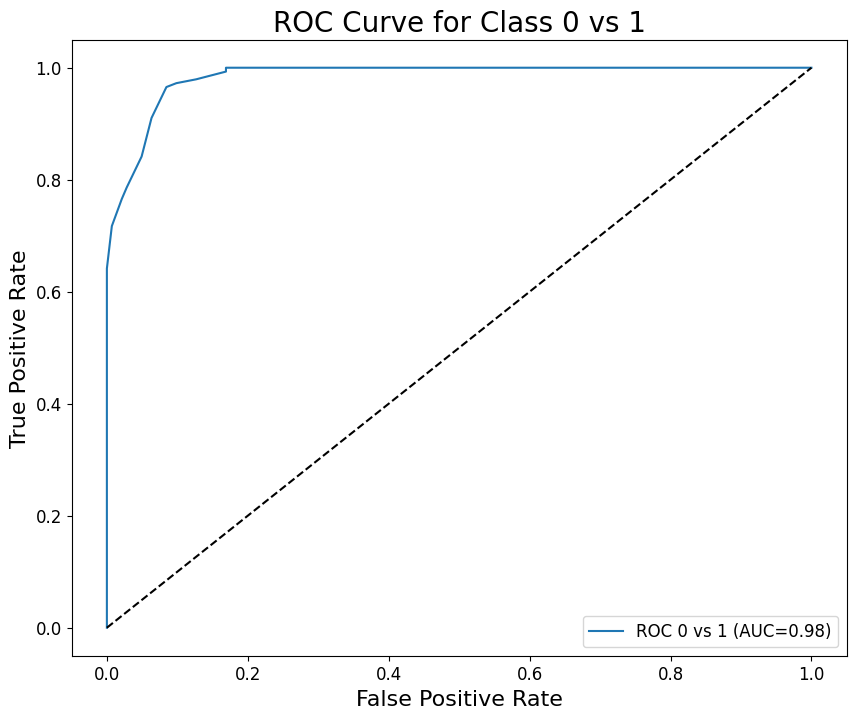

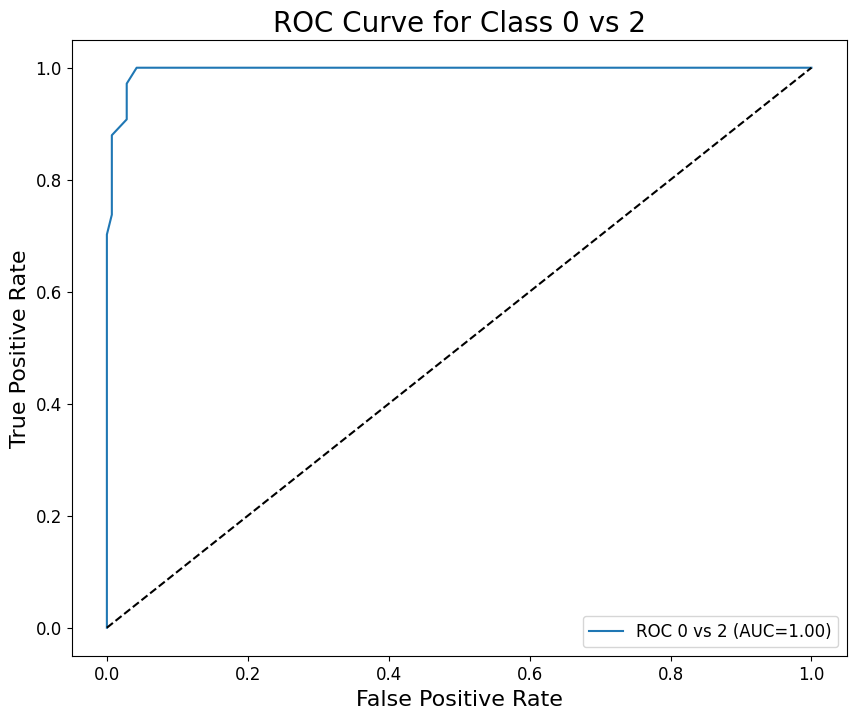

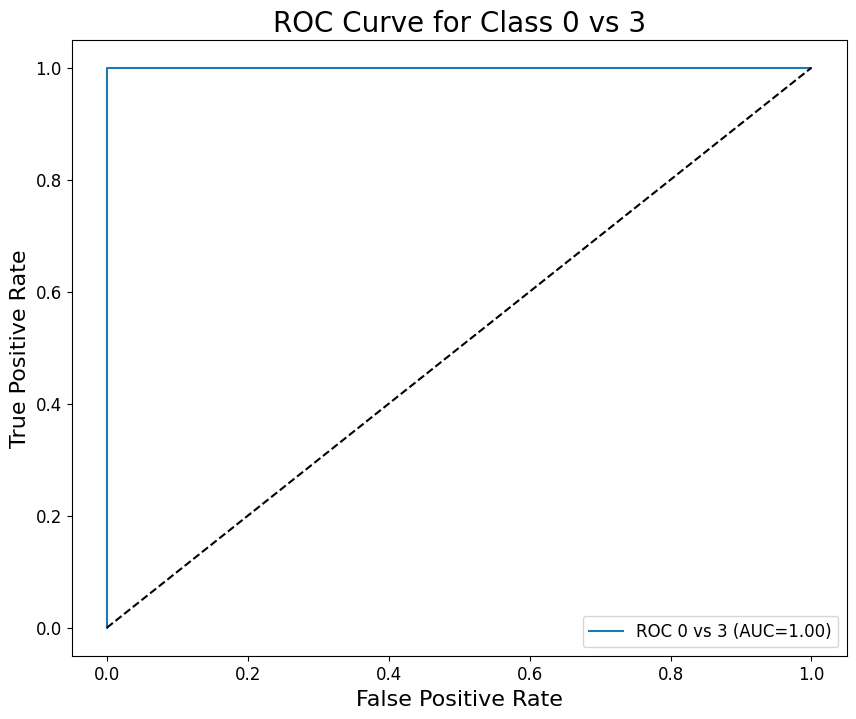

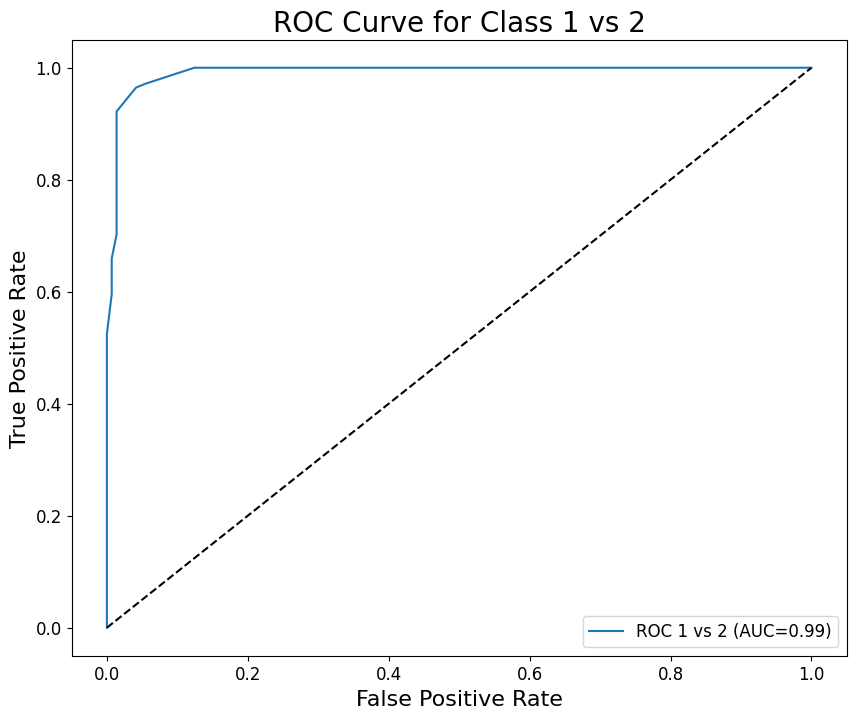

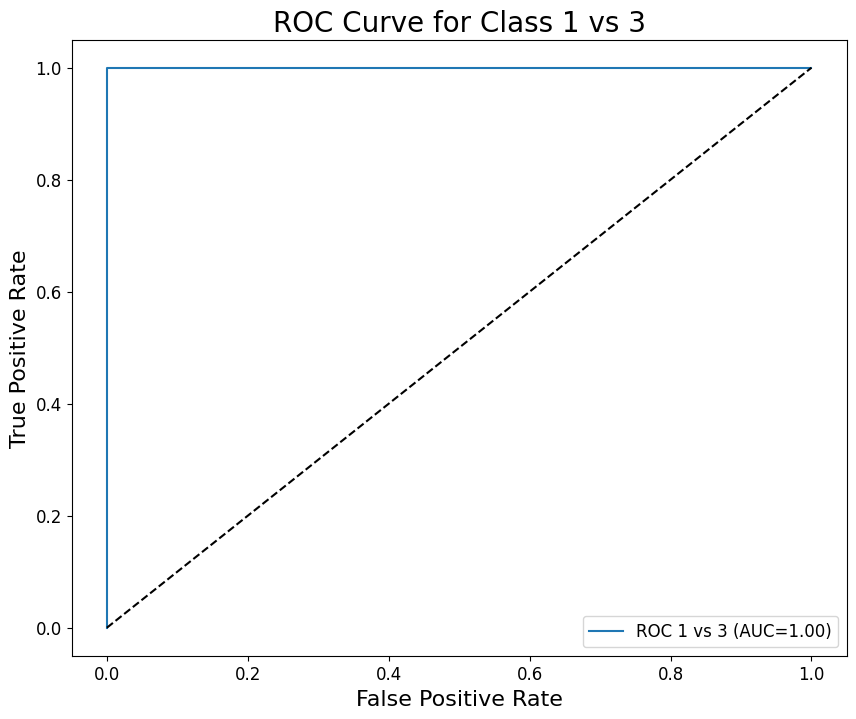

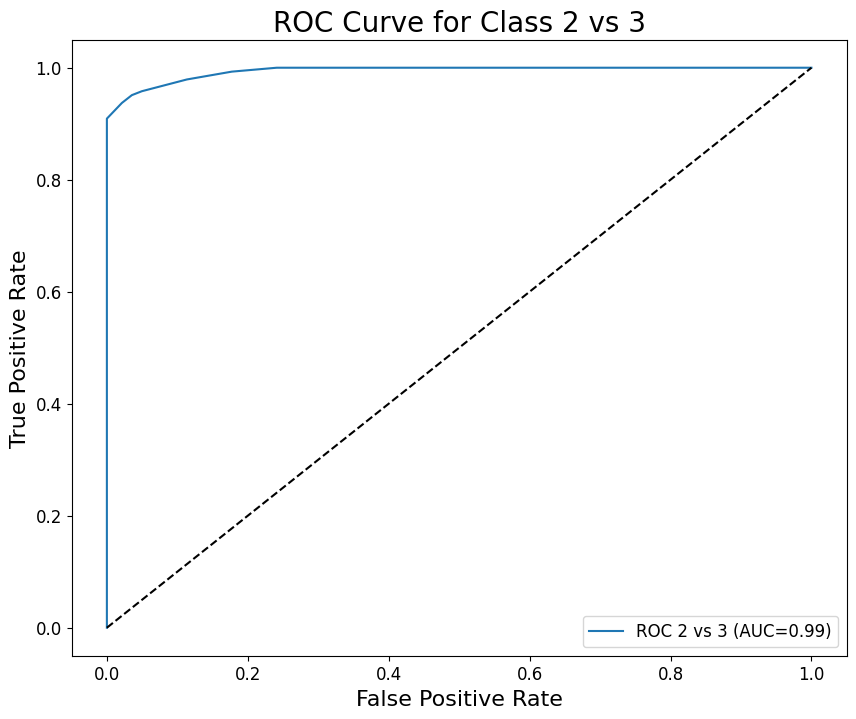

       Class  ROC 0 vs 1  ROC 0 vs 2  ROC 0 vs 3  ROC 1 vs 2  ROC 1 vs 3  \
0  AUC value    0.983827     0.99558         1.0    0.991783         1.0   

   ROC 2 vs 3  
0    0.993801  


In [237]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
import pandas as pd


def compute_roc_for_pairs(y_test, y_pred_probs):
    """
    This function plots the ROC curve for each distinct pair and records AUC.

    Arguments:
    y_test: Testing labels
    y_pred_probs: Predicted probabilities from the soft decision tree

    Returns:
    A DataFrame containing the AUC values for each class pair
    """
    y_pred_probs = np.array(y_pred_probs)
    classes = np.unique(y_test)
    class_pairs = list(([0, 1], [0, 2], [0, 3], [1, 2], [1, 3], [2, 3]))

    # Initialize an empty dictionary to store AUC results
    result = {}
    result[f"Class"] = ["AUC value"]

    # Iterate through the class pairs
    for class_a, class_b in class_pairs:
        mask = (y_test == class_a) | (y_test == class_b)
        y_binary = y_test[mask] == class_b  # Convert to binary 0/1

        y_probs = y_pred_probs[mask, class_b]  # Predicted probabilities for class_b

        fpr, tpr, _ = roc_curve(y_binary, y_probs)
        auc_value = auc(fpr, tpr)  # Compute AUC

        # Store the AUC for the current class pair in the result dictionary
        result[f"ROC {class_a} vs {class_b}"] = [auc_value]

        # Plot the ROC curve
        plt.figure(figsize=(10, 8))
        plt.plot(fpr, tpr, label=f"ROC {class_a} vs {class_b} (AUC={auc_value:.2f})")
        plt.plot([0, 1], [0, 1], "k--")  # Random classifier line
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.title(f"ROC Curve for Class {class_a} vs {class_b}")
        plt.legend()
        plt.show()

    # Convert the result dictionary into a DataFrame and return
    roc_df = pd.DataFrame(result)
    return roc_df


# Example call
roc_dataframe = compute_roc_for_pairs(y_train, soft_result)
print(roc_dataframe)

<a name="task-13"></a>

## (1.3) [(index)](#index-task-13)

In [238]:
def gini_split_rf(n_features, X, y, cat_columns_dict):
    """
    Choose the best feature to split according to criterion.
    Args:
        n_features: number of sampled features.
        X: training features, of shape (N, p).
        y: vector of training labels, of shape (N,).
        cat_columns_dict: a dictionary mapping column indices to whether the column is categorical or numerical variable.
    Returns:
        (float, int, float): the minimized gini-index, the best feature index and value used in splitting.
    """

    # The added sampling step.
    columns = rng.choice(list(cat_columns_dict.keys()), n_features, replace=False)
    cat_columns_dict = {c: cat_columns_dict[c] for c in columns}

    min_gini_index, split_column, split_val = np.inf, 0, 0

    # Only scan through the sampled columns in `cat_columns_dict`.
    for column, categorical in cat_columns_dict.items():
        # skip column if samples are not separable by that column.
        if len(np.unique(X[:, column])) < 2:
            continue

        # search for the best splitting value for the given column.
        gini_index, val = gini_split_value(X, y, column, categorical)
        if gini_index < min_gini_index:
            min_gini_index, split_column, split_val = gini_index, column, val

    return min_gini_index, split_column, split_val

gini_importance_dict = {} 

In [239]:
def build_tree_rf(n_features, X, y, cat_columns_dict, feature_names, depth, number_of_total_samples, max_depth=10, min_samples_leaf=12):
    """构建决策树，并计算 Gini 重要性."""
    
    number_of_samples = len(X)

    p_t = number_of_samples/number_of_total_samples
    
    if len(np.unique(y)) == 1 or depth > max_depth or len(X) <= min_samples_leaf:
        return {'majority_label': majority_vote(y),
                'number_of_samples': number_of_samples,
                'Gini_index': 0}
    
    GI, split_column, split_val = gini_split_rf(n_features, X, y, cat_columns_dict)
    
    if GI == np.inf:
        return {'majority_label': majority_vote(y),
                'number_of_samples': number_of_samples,
                'Gini_index': 0}
    
    categorical = cat_columns_dict[split_column]
    (X_l, y_l), (X_r, y_r) = split_samples(X, y, split_column, split_val, categorical)
    
    GI_t = gini_index(y)
    GI_tL = gini_index(y_l) #if len(y_l) > 0 else 0
    GI_tR = gini_index(y_r) #if len(y_r) > 0 else 0
    
    p_L = len(y_l) / number_of_samples #if len(y_l) > 0 else 0
    p_R = len(y_r) / number_of_samples #if len(y_r) > 0 else 0
    
    delta_GI = GI_t - (p_L * GI_tL + p_R * GI_tR)

    
    if feature_names[split_column] in gini_importance_dict:
        gini_importance_dict[feature_names[split_column]] += p_t * delta_GI
    else:
        gini_importance_dict[feature_names[split_column]] = p_t * delta_GI
    
    return {
        'feature_name': feature_names[split_column],
        'feature_index': split_column,
        'value': split_val,
        'categorical': categorical,
        'majority_label': None,
        'number_of_samples': number_of_samples,
        'Gini_index': GI,
        'left': build_tree_rf(n_features, X_l, y_l, cat_columns_dict, feature_names, depth + 1, number_of_total_samples, max_depth, min_samples_leaf),
        'right': build_tree_rf(n_features, X_r, y_r, cat_columns_dict, feature_names, depth + 1, number_of_total_samples, max_depth, min_samples_leaf)
    }


In [240]:
def train_rf(B, n_features, X, y,  cat_columns_dict, max_depth=10):
    """
    Resample B datasets from the training data and build a decision tree for each of them.
    Args:
        B: number of decision trees.
        X: (pd.Dataframe) training features, of shape (N, p). Each X[i] is a training sample.
        y: (pd.Series) vector of training labels, of shape (N,). y[i] is the label for X[i], and each y[i] is
        an integer in the range 0 <= y[i] <= C. Here C = 1.
        cat_columns_dict: a dictionary mapping column indices to whether the column is categorical or numerical variable.
    """

    feature_names = X.columns.tolist()
    X = X.to_numpy()
    y = y.to_numpy()
    N = X.shape[0]
    training_indices = np.arange(N)
    trees = []

    for _ in range(B):
        # Sample the training_indices (with replacement)
        sample = rng.choice(training_indices, N, replace=True)
        X_sample = X[sample, :]
        y_sample = y[sample]
        tree = build_tree_rf(n_features, X_sample, y_sample,
                        cat_columns_dict, feature_names, depth=1, number_of_total_samples=N, max_depth=max_depth)
        trees.append(tree)

    return trees

def aggregate(decisions):
    """
    This function takes a list of predicted labels produced by a list
    of decision trees and returns the label with the majority of votes.
    """
    count = defaultdict(int)
    for decision in decisions:
        count[decision] += 1
    return max(count, key=count.get)

def predict_rf(rf, X):
    """
    Predict classification results for X.
    Args:
        rf: A trained random forest through train_rf function.
        X: (pd.Dataframe) testing sample features, of shape (N, p).
    Returns:
        (np.array): predicted testing sample labels, of shape (N,).
    """

    if len(X.shape) == 1:
        # if we have one sample
        return aggregate([classify(tree, X) for tree in rf])
    else:
        # if we have multiple samples
        return np.array([aggregate([classify(tree, x) for tree in rf]) for x in X])

def rf_score(rf, X_test, y_test):
    y_pred = predict_rf(rf, X_test)
    return np.mean(y_pred==y_test)

In [241]:
gini_importance_dict

{}

In [242]:
def plot_gini_importance():
    
    normalized_importance = gini_importance_dict

    plt.figure(figsize=(10, 5))
    plt.bar(normalized_importance.keys(), normalized_importance.values(), color='b')
    plt.xticks(range(len(feature_names)), feature_names, rotation=45, ha="right")
    plt.xlabel("Features")
    plt.ylabel("Gini Importance")
    plt.title("Feature Importance based on Gini Index")
    plt.xticks(rotation=45)
    plt.show()


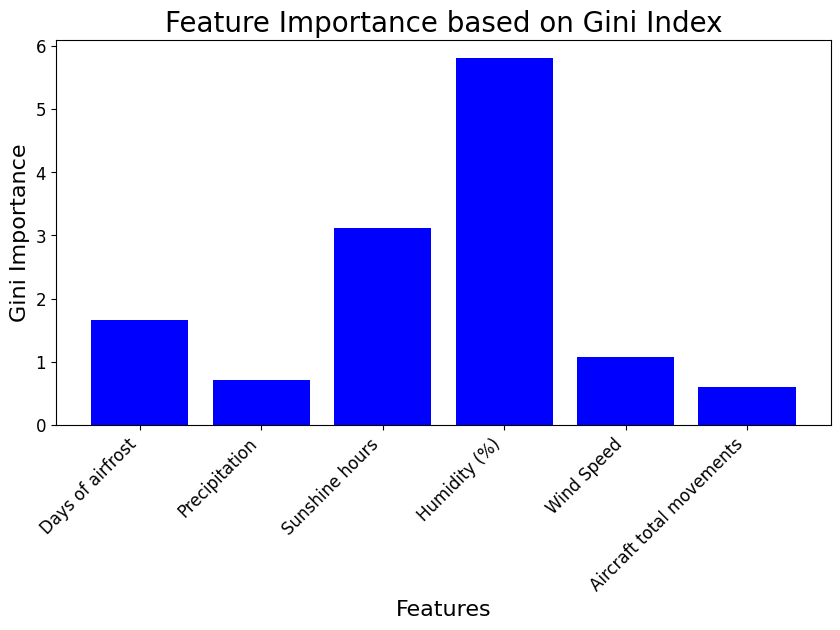

In [243]:
B = 20
n_features = int(np.sqrt(6)) 
X1 = pd.DataFrame(X_train)
Y1 = pd.DataFrame(y_train)
rf = train_rf(B, 2, X1, Y1, cat_columns_dict = cat_columns_dict)
plot_gini_importance()

<a name="task-14"></a>

## (1.4) [(index)](#index-task-14)

In [244]:
import numpy as np

N = len(X_train)
B = [10]
training_indices = np.arange(N)
oob_errors = np.zeros(len(B))

rng = np.random.default_rng() 
n_features = X_train.shape[1]
max_depth = 10

X = X_train
y = y_train
for j in range(len(B)):
    trees = []
    oob_predictions = {i: [] for i in range(N)}

    for ind in range(B[j]):
        sample = rng.choice(training_indices, N, replace=True)
        sample = sorted(sample)
        oob_samples_index = sorted(list(set(training_indices) - set(sample)))
        oob_samples_X = np.take(X, oob_samples_index, axis=0)
        oob_samples_y = np.take(y, oob_samples_index, axis=0)
        X_sample = X_train[sample, :]
        y_sample = y_train[sample]

        tree = build_tree_rf(n_features, X_sample, y_sample, cat_columns_dict, feature_names, number_of_total_samples=X_train.shape[0],
                             depth=1, max_depth=max_depth)
        trees.append(tree)

        prediction = predict_rf(trees, oob_samples_X)
        oob_error = np.mean(prediction != oob_samples_y)

        oob_errors[j] += oob_error

    oob_errors[j] /= B[j]
    print(f"B = {B[j]}, Averaged OOB Error: {oob_errors[j]:.4f}")

optimal_B = B[np.argmin(oob_errors)]
print(f"Optimal B: {optimal_B}")


B = 10, Averaged OOB Error: 0.0941
Optimal B: 10


<a name="task-2"></a>

# Task 2: Binary classification with the Huberised Support Vector Machine [(index)](#index-task-2)

In [245]:
def standardise(X, X_train_=None):
    """
    Standardise features.

    Parameters:
        X (np.array): Feature matrix.
        X_train_ (np.array): An optional feature matrix to compute the statistics
            from before applying it to X. If None, just use X to compute the statistics.

    Returns:
        X_std (np.array): Standardised feature matrix
    """
    if X_train_ is None:
        X_train_ = X

    mu = np.mean(X_train_, axis=0, keepdims=True)
    sigma = np.std(X_train_, axis=0, keepdims=True)
    X_std = (X - mu) / sigma

    return X_std

In [246]:
X_train = X_train_origin.copy()
X_test = X_test_origin.copy()

y_train = y_train_origin.copy()
y_test = y_test_origin.copy()

y_train[y_train_origin==0] = 1
y_train[y_train_origin!=0] = -1

y_test[y_test_origin==0] = 1
y_test[y_test_origin!=0] = -1
# We standardise both training and test sets
X_train_std = standardise(X_train) ## <-- SOLUTION
X_test_std = standardise(X_test, X_train) ## <-- SOLUTION

# Insert 1 in every row for intercept b
X_train_intercept = np.hstack((X_train_std, np.ones((len(X_train_std), 1))))
X_test_intercept = np.hstack((X_test_std, np.ones((len(X_test_std), 1))))

xy_train = np.column_stack((X_train, y_train))
xy_test = np.column_stack((X_test, y_test))

xy_train_std = np.hstack((X_train_std, y_train.reshape(-1,1)))
xy_test_std = np.hstack((X_test_std, y_test.reshape(-1,1)))


<a name="task-21"></a>

## (2.1) Modified Huber function vs hinge loss [(index)](#index-task-21)

We start by defining the Huber loss function:
$$
L (\mathbf{w}, b) = \frac{1}{2} \| \mathbf{w} \|^2 + \lambda \sum_{i=1}^N L_c \Big( 1 - y^{(i)} (\mathbf{x}^{(i)} \cdot \mathbf{w} + b) \Big),
$$

in which ：
$$
L_c(z) =
\begin{cases}
0, & z \leq 0, \\
\frac{1}{2}z^2, & 0 < z \leq c, \\
c(z - \frac{c}{2}), & z > c.
\end{cases}
$$


In [247]:
# EDIT THIS FUNCTION
def L_c(z, c=1):
    """
    Compute the function L_c(z)

    Parameters:
        z: Input number
        c: Function parameter

    Returns:
        The result of the function

    """

    if z <= 0:
        return 0
    
    if 0 < z <= c:
        return 0.5*z**2
    
    else:
        return c*(z-c*0.5)


def compute_loss_Huber(w, X, y, regul_strength=1e2):
    """
    Compute the loss function for linear SVM.

    Parameters:
        w (np.array): Vector of weights (incl. bias).
        X (np.array): Input features.
        y (np.array): Labels.
        regul_strength (float): Regularisation parameter.

    Returns:
        loss (float): Loss function as given by the equation above.

    """

    n = X.shape[0]
    distances = 1 - y * (X @ w)  ## <-- SOLUTION
    loss_terms = np.array([L_c(d) for d in distances]) 

    hinge_loss = np.sum(loss_terms)
    reg_term = 0.5 * np.dot(w[:-1], w[:-1])

    return reg_term + regul_strength * hinge_loss

Then, I used the mini-batch optimiser to find the optimal value. First define the loss_gradient of Huber loss function

In [248]:
# EDIT THIS FUNCTION
def calculate_loss_gradient_Huber(w, X_batch, y_batch, c=1, regul_strength=1e2):
    """
    Calculate gradient of the loss.

    Parameters:
        w (np.array): Vector of weights (incl. bias).
        X_batch (np.array): Batch of input features.
        y_batch (np.array): Batch of labels.
        regul_strength (float): Regularisation parameter.

    Returns:
        grad_w (float): Gradient of the loss with respect to w.

    """

    # If only one sample is passed
    if type(y_batch) == np.float64:
        y_batch = np.asarray([y_batch])
        X_batch = np.asarray([X_batch])  # gives multidimensional array

    distance = 1 - (y_batch * (X_batch @ w))
    dw = np.zeros(len(w))

    we = w.copy() # So as not to overwrite w
    b = w[-1]
    we[-1] = 0 # So as not to have b in its derivative when adding the weights in di

    for ind, d in enumerate(distance):
        if d <=  0: ## <-- SOLUTION
            di = we ## <-- SOLUTION

        elif 0 < d <= c:
            di = we - regul_strength*y_batch[ind] * X_batch[ind]*d
            
        else:
            di = we - c*regul_strength*y_batch[ind] * X_batch[ind] 
            
        dw += di

    dw /= len(y_batch) # average

    return dw

The two functions described earlier are then used with the **mini-batch stochastic gradient descent** algorithm to iteratively update the model weights using a given learning rate, $\eta$. Additionally, a stopping criterion is implemented to terminate the training process when the loss function changes by less than a specified percentage.

The updates of e.g. weights during training are governed by the following rule:

$$
\mathbf{w}_{t+1} = \mathbf{w}_{t} - \eta \nabla_{\mathbf{w}} L(\mathbf{w}_t, b_t; S_m)
$$
where $\nabla_{\mathbf{w}} L(\mathbf{w}_t, b_t; S_m)$ is the gradient the mean loss function over a randomly sampled mini-batch $S_m$.

In [249]:
# EDIT THIS FUNCTION
def mini_batch_gradient_descent_Huber(X, y, batch_size=32, max_iterations=2000, stop_criterion=0.001, learning_rate=1e-4, c=1, regul_strength=1e2, print_outcome=False):
    """
    Performs mini-batch stochastic gradient descent to optimise weights.

    Parameters:
        X (np.array): The feature matrix.
        y (np.array): The target labels.
        batch_size (int): Size of each mini-batch.
        max_iterations (int): Maximum number of iterations.
        stop_criterion (float): Percentage change in loss function to determine convergence.
        learning_rate (float): Learning rate for gradient updates.
        regul_strength (float): Regularisation parameter
        print_outcome (bool): Whether to print progress during training.

    Returns:
        weights (np.array): Optimised weights.
        loss_history (list): History of loss.
        iteration_list (list): List of iteration numbers corresponding to the loss values.

    """
    # Initialise weights to zero
    weights = np.zeros(X.shape[1])
    nth = 0
    prev_loss = np.inf  # Initialise starting loss as infinity
    loss_history = []  # Track loss values
    iteration_list = []  # Track iteration numbers

    for iteration in range(1, max_iterations+1):
        # Shuffle data to prevent repeating update cycles
        indices = np.random.permutation(len(y))
        X_shuffled, y_shuffled = X[indices], y[indices] ## <-- SOLUTION

        # Create mini-batches
        for start_idx in range(0, len(y), batch_size):
            end_idx = start_idx + batch_size
            X_batch = X_shuffled[start_idx:end_idx] ## <-- SOLUTION
            y_batch = y_shuffled[start_idx:end_idx] ## <-- SOLUTION

            # Compute the gradient for the mini-batch
            gradient = calculate_loss_gradient_Huber(weights, X_batch, y_batch) ## <-- SOLUTION

            # Update weights
            weights = weights - (learning_rate * gradient) ## <-- SOLUTION

        # Check for convergence at 2^nth iteration or last iteration
        if iteration == 2**nth or iteration == max_iterations:
            # Compute the current loss
            loss = compute_loss_Huber(weights, X, y, regul_strength) ## <-- SOLUTION
            if print_outcome:
                print(f'Iteration: {iteration}, Loss: {loss:.6f}')

            # Check if the stop criterion is met
            if abs(prev_loss - loss) < stop_criterion * prev_loss: ## <-- SOLUTION
                return weights, loss_history, iteration_list

            # Update tracking variables
            prev_loss = loss
            iteration_list.append(iteration)
            loss_history.append(loss)
            nth += 1

    return weights, loss_history, iteration_list


In [250]:

w, loss_history, iterations = mini_batch_gradient_descent_Huber(X_train_intercept, y_train, batch_size=32, max_iterations=2000, stop_criterion=0.001, learning_rate=1e-4, regul_strength=1e2, print_outcome=True)
print('Training finished.')

Iteration: 1, Loss: 24620.768127
Iteration: 2, Loss: 22035.239273
Iteration: 4, Loss: 18960.314600
Iteration: 8, Loss: 16071.125663
Iteration: 16, Loss: 13732.788160
Iteration: 32, Loss: 11460.525406
Iteration: 64, Loss: 9371.457213
Iteration: 128, Loss: 7801.526332
Iteration: 256, Loss: 6739.321218
Iteration: 512, Loss: 6191.848851
Iteration: 1024, Loss: 6005.878244
Iteration: 2000, Loss: 5977.611949
Training finished.


Here I plotted the training loss of Huberised SVM

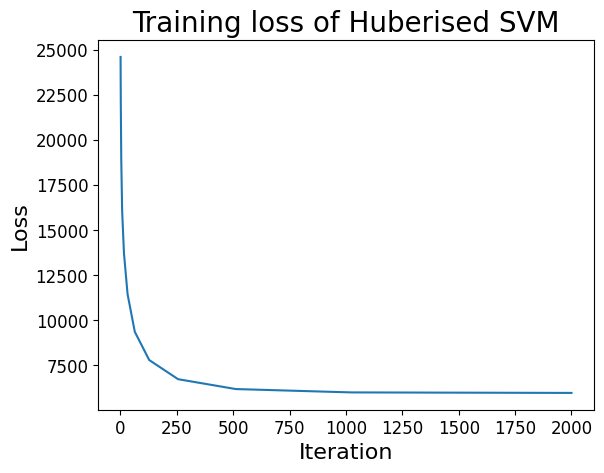

In [251]:
plt.plot(iterations, loss_history)
plt.title(f'Training loss of Huberised SVM')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.show()

For comparison, I used the code for hinge loss from note Supporter Vector Machine with a little adaptation.

In [252]:
# EDIT THIS FUNCTION
def compute_loss(w, X, y, regul_strength=1e5):
    """
    Compute the loss function for linear SVM.

    Parameters:
        w (np.array): Vector of weights (incl. bias).
        X (np.array): Input features.
        y (np.array): Labels.
        regul_strength (float): Regularisation parameter.

    Returns:
        loss (float): Loss function as given by the equation above.

    """

    n = X.shape[0]
    distances = 1 - y * (X @ w)  ## <-- SOLUTION
    distances[distances < 0] = 0  # equivalent to max(0, distance)
    hinge = distances.sum() ## <-- SOLUTION

    # calculate loss
    return 0.5 * np.dot(w, w) + regul_strength * hinge - 0.5 * w[-1] ** 2

# EDIT THIS FUNCTION
def calculate_loss_gradient(w, X_batch, y_batch, regul_strength=1e6):
    """
    Calculate gradient of the loss.

    Parameters:
        w (np.array): Vector of weights (incl. bias).
        X_batch (np.array): Batch of input features.
        y_batch (np.array): Batch of labels.
        regul_strength (float): Regularisation parameter.

    Returns:
        grad_w (float): Gradient of the loss with respect to w.

    """

    # If only one sample is passed
    if type(y_batch) == np.float64:
        y_batch = np.asarray([y_batch])
        X_batch = np.asarray([X_batch])  # gives multidimensional array

    distance = 1 - (y_batch * (X_batch @ w))
    dw = np.zeros(len(w))

    we = w.copy() # So as not to overwrite w
    we[-1] = 0 # So as not to have b in its derivative when adding the weights in di

    for ind, d in enumerate(distance):
        if max(0, d) == 0: ## <-- SOLUTION
            di = we ## <-- SOLUTION
        else:
            di = we - (regul_strength * y_batch[ind] * X_batch[ind]) ## <-- SOLUTION
        dw += di

    dw /= len(y_batch) # average

    return dw

# EDIT THIS FUNCTION
def mini_batch_gradient_descent(X, y, batch_size=32, max_iterations=2000, stop_criterion=0.01, learning_rate=1e-5, regul_strength=1e6, print_outcome=False):
    """
    Performs mini-batch stochastic gradient descent to optimise weights.

    Parameters:
        X (np.array): The feature matrix.
        y (np.array): The target labels.
        batch_size (int): Size of each mini-batch.
        max_iterations (int): Maximum number of iterations.
        stop_criterion (float): Percentage change in loss function to determine convergence.
        learning_rate (float): Learning rate for gradient updates.
        regul_strength (float): Regularisation parameter
        print_outcome (bool): Whether to print progress during training.

    Returns:
        weights (np.array): Optimised weights.
        loss_history (list): History of loss.
        iteration_list (list): List of iteration numbers corresponding to the loss values.

    """
    # Initialise weights to zero
    weights = np.zeros(X.shape[1])
    nth = 0
    prev_loss = np.inf  # Initialise starting loss as infinity
    loss_history = []  # Track loss values
    iteration_list = []  # Track iteration numbers

    for iteration in range(1, max_iterations+1):
        # Shuffle data to prevent repeating update cycles
        indices = np.random.permutation(len(y))
        X_shuffled, y_shuffled = X[indices], y[indices] ## <-- SOLUTION

        # Create mini-batches
        for start_idx in range(0, len(y), batch_size):
            end_idx = start_idx + batch_size
            X_batch = X_shuffled[start_idx:end_idx] ## <-- SOLUTION
            y_batch = y_shuffled[start_idx:end_idx] ## <-- SOLUTION

            # Compute the gradient for the mini-batch
            gradient = calculate_loss_gradient(weights, X_batch, y_batch, regul_strength) ## <-- SOLUTION

            # Update weights
            weights = weights - (learning_rate * gradient) ## <-- SOLUTION

        # Check for convergence at 2^nth iteration or last iteration
        if iteration == 2**nth or iteration == max_iterations:
            # Compute the current loss
            loss = compute_loss(weights, X, y, regul_strength) ## <-- SOLUTION
            if print_outcome:
                print(f'Iteration: {iteration}, Loss: {loss:.6f}')

            # Check if the stop criterion is met
            if abs(prev_loss - loss) < stop_criterion * prev_loss: ## <-- SOLUTION
                return weights, loss_history, iteration_list

            # Update tracking variables
            prev_loss = loss
            iteration_list.append(iteration)
            loss_history.append(loss)
            nth += 1

    return weights, loss_history, iteration_list



Still, I calculate the hinge loss and plotted the graph.

In [253]:
w_1, loss_history_1, iterations_1 = mini_batch_gradient_descent(
    X_train_intercept,
    y_train,
    batch_size=32,
    max_iterations=2000,
    stop_criterion=0.001,
    learning_rate=1e-4,
    regul_strength=1e2,
    print_outcome=True,
)
print("Training finished.")

Iteration: 1, Loss: 52164.969060
Iteration: 2, Loss: 47387.252973
Iteration: 4, Loss: 39968.125365
Iteration: 8, Loss: 32837.092669
Iteration: 16, Loss: 26261.643361
Iteration: 32, Loss: 24257.576987
Iteration: 64, Loss: 21659.442879
Iteration: 128, Loss: 17251.274570
Iteration: 256, Loss: 13702.014198
Iteration: 512, Loss: 12206.883806
Iteration: 1024, Loss: 11803.505153
Iteration: 2000, Loss: 11706.974878
Training finished.


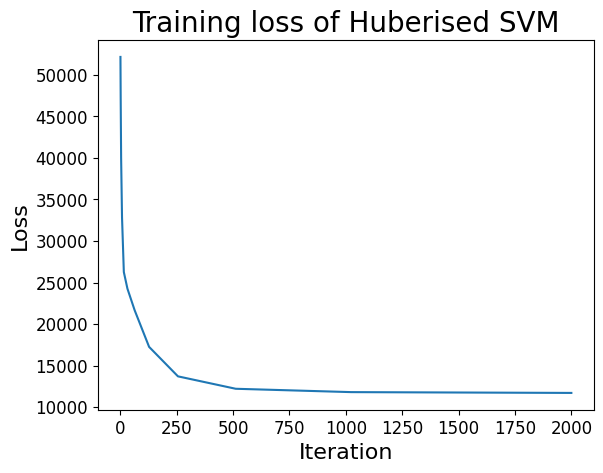

In [254]:
plt.plot(iterations_1, loss_history_1)
plt.title(f"Training loss of Huberised SVM")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

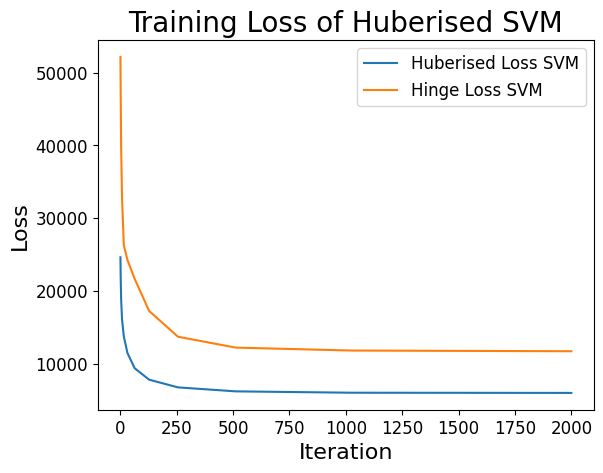

In [255]:

plt.plot(iterations, loss_history, label="Huberised Loss SVM")
plt.plot(iterations_1, loss_history_1, label="Hinge Loss SVM")

plt.title("Training Loss of Huberised SVM")
plt.xlabel("Iteration")
plt.ylabel("Loss")

plt.legend()

plt.show()

With the comparison, I can conclude that huberised loss function provides a better measurement for the loss in this particular case, and the huberised loss function after iterations is much smaller than the hinge loss

In [256]:
## EDIT THIS FUNCTION
def score(w, X, y):
    """
    Computes the mean accuracy.

    Parameters:
        w (np.array): Vector of weights (incl. bias).
        X (np.array): The feature matrix.
        y (np.array): The target labels.

    Returns:
        mean_accuracy (np.array): Optimised weights.

    """
    y_preds = np.sign(X @ w)
    mean_accuracy = np.mean(y_preds == y) ## <-- SOLUTION

    return mean_accuracy

def balanced_score(w, X, y):
    """
    Computes the mean accuracy.

    Parameters:
        w (np.array): Vector of weights (incl. bias).
        X (np.array): The feature matrix.
        y (np.array): The target labels.

    Returns:
        mean_accuracy (np.array): Accuracy score.

    """
    y_preds = np.sign(X @ w)
    P = np.mean(y_preds[y_preds > 0] == y[y_preds > 0])
    N = np.mean(y_preds[y_preds <= 0] == y[y_preds <= 0])
    balanced_accuracy = 0.5*(P + N)

    return balanced_accuracy

In [257]:
print("Accuracy on training set with Huberised Loss SVM: {}".format(score(w, X_train_intercept, y_train)))
print("Accuracy on test set with Huberised Loss SVM: {}".format(score(w, X_test_intercept, y_test)))
print("Balanced Accuracy on training set with Huberised Loss SVM: {}".format(balanced_score(w, X_train_intercept, y_train)))
print("Balanced Accuracy on test set with Huberised Loss SVM: {}".format(balanced_score(w, X_test_intercept, y_test)))

Accuracy on training set with Huberised Loss SVM: 0.9474605954465849
Accuracy on test set with Huberised Loss SVM: 0.9346938775510204
Balanced Accuracy on training set with Huberised Loss SVM: 0.9314385150812066
Balanced Accuracy on test set with Huberised Loss SVM: 0.921537894154527


In [258]:
print("Accuracy on training set with Hinge Loss SVM: {}".format(score(w_1, X_train_intercept, y_train)))
print("Accuracy on test set with Hinge Loss SVM: {}".format(score(w_1, X_test_intercept, y_test)))
print("Balanced Accuracy on training set with Hinge Loss SVM: {}".format(balanced_score(w_1, X_train_intercept, y_train)))
print("Balanced Accuracy on test set with Hinge Loss SVM: {}".format(balanced_score(w_1, X_test_intercept, y_test)))

Accuracy on training set with Hinge Loss SVM: 0.9527145359019265
Accuracy on test set with Hinge Loss SVM: 0.9346938775510204
Balanced Accuracy on training set with Hinge Loss SVM: 0.9358620351611006
Balanced Accuracy on test set with Hinge Loss SVM: 0.921537894154527


Here I defined a function to calculate the falling outside data points.

In [290]:
def fall_outside(w, X, y):
    """
    Computes the mean accuracy.

    Parameters:
        w (np.array): Vector of weights (incl. bias).
        X (np.array): The feature matrix.
        y (np.array): The target labels.

    Returns:
        number of points falling outside the margin

    """


    distantia = 1- y*(X@w)

    numerus = 0
    for d in distantia:

        if d > 0:

            numerus += 1
    return numerus

In [285]:
print(
    "The number of training datapoints falling outside the SVM with Huberised Loss: {}".format(
        fall_outside(
            w, X_train_intercept, y_train
        )
    )
)
print(
    "The number training datapoints falling outside the SVM with Hinge Loss: {}".format(
        fall_outside(w_1, X_train_intercept, y_train)
    )
)
print(
    "The number of test datapoints falling outside the SVM with Huberised Loss: {}".format(
        fall_outside(w, X_test_intercept, y_test)
    )
)
print(
    "The number of test datapoints falling outside the SVM with Hinge Loss: {}".format(
        fall_outside(w_1, X_test_intercept, y_test)
    )
)

The number of training datapoints falling outside the SVM with Huberised Loss: 279
The number training datapoints falling outside the SVM with Hinge Loss: 192
The number of test datapoints falling outside the SVM with Huberised Loss: 112
The number of test datapoints falling outside the SVM with Hinge Loss: 81


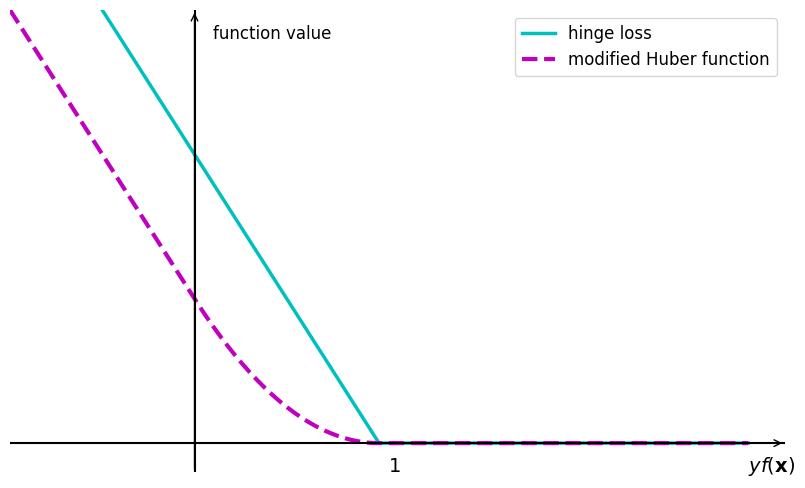

In [289]:
import numpy as np
import matplotlib.pyplot as plt

# Generalise points in the interested yf(x) value range
yfx = np.linspace(-1, 3, 201, endpoint=True)
c_Huber = 1

# Compute the hinge loss value
hinge_loss_yfx = 1 - yfx
hinge_loss_yfx[hinge_loss_yfx < 0] = 0

# Compute the Huber function value
Huber_function_yfx = np.zeros(len(yfx))
for index, z in enumerate(1 - yfx):
    if z > c_Huber:
        Huber_function_yfx[index] = c_Huber * (z - 0.5 * c_Huber)
    elif z > 0:
        Huber_function_yfx[index] = 0.5 * z**2

# Create a single plot
fig, ax = plt.subplots(figsize=(10, 6), facecolor="white")

# Plot the functions with new color and style choices
ax.plot(yfx, hinge_loss_yfx, "c-", linewidth=2.5, label="hinge loss")  # Cyan solid line
ax.plot(
    yfx, Huber_function_yfx, "m--", linewidth=3, label="huber loss"
)  # Magenta dashed line

# Customize plot appearance similar to the lecture note style
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.axhline(0, color="black", linewidth=1.5)
ax.axvline(0, color="black", linewidth=1.5)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlim(-1, 3.2)
ax.set_ylim(-0.1, 1.5)

# Add axis annotations and labels
ax.annotate(
    "", xy=(3.2, 0), xytext=(-1, 0), arrowprops=dict(arrowstyle="->", color="black")
)
ax.annotate(
    "", xy=(0, 1.5), xytext=(0, -0.1), arrowprops=dict(arrowstyle="->", color="black")
)
ax.text(0.1, 1.4, r"function value", fontsize=12)
ax.text(1.05, -0.1, r"$1$", fontsize=14)
ax.text(3, -0.1, r"$yf(\mathbf{x})$", fontsize=14)

# Add a legend to distinguish the plots
ax.legend()

plt.show()

With the results, I am able to conclude that 

<a name="task-22"></a>

## (2.2) [(index)](#index-task-22)

In [260]:
def score(w, X, y):
    """
    Computes the mean accuracy.

    Parameters:
        w (np.array): Vector of weights (incl. bias).
        X (np.array): The feature matrix.
        y (np.array): The target labels.

    Returns:
        mean_accuracy (np.array): Optimised weights.

    """
    y_preds = np.sign(X @ w)
    mean_accuracy = np.mean(y_preds == y) ## <-- SOLUTION

    return mean_accuracy

print('Accuracy on training set: {}'.format(score(w, X_train_intercept, y_train)))
print('Accuracy on test set: {}'.format(score(w, X_test_intercept, y_test)))

Accuracy on training set: 0.9474605954465849
Accuracy on test set: 0.9346938775510204


In [261]:
def cross_val_split(num_samples, num_folds):
    """
    Splits the dataset indices into `num_folds` folds for cross-validation.

    Parameters:
        num_samples (int): The total number of samples in the dataset.
        num_folds (int): The number of folds for cross-validation.

    Returns:
        fold (list[np.array]): A list of numpy arrays containing the indices defining the validation set for one fold.
    """

    fold_size = num_samples // num_folds
    shuffled_indices = np.random.permutation(np.arange(num_samples))
    folds = [
        shuffled_indices[k * fold_size : (k + 1) * fold_size]
        for k in range(num_folds)
    ]  ## <-- SOLUTION

    return folds

In [262]:

def cross_val_evaluate_old(data, num_folds, c_values=1, regul_strength_values=100):
    """
    Performs T-fold cross-validation on the given dataset to find the optimal regul_strength.

    Parameters:
        data (np.array): The dataset, where the last column contains the target labels.
        num_folds (int): The number of folds for cross-validation.
        regul_strength_values (list): A list of regularisation strength values to evaluate.

    Returns:
        tuple: A tuple containing two lists:
            - train_scores (list): Accuracy scores on the training set for each regul_strength.
            - val_scores (list): Accuracy scores on the validation set for each regul_strength.
    """


    if regul_strength_values != 100:
        folds = cross_val_split(data.shape[0], num_folds) # Get indicies to split data
        train_scores = np.zeros(len(regul_strength_values))
        validation_scores = np.zeros(len(regul_strength_values))

        for j, regularisation_strength in enumerate(regul_strength_values):
            print(f'\nEvaluating regul_strength: {regularisation_strength}')

            for i, validation_indices in enumerate(folds):

                # Define the training and validation sets
                train_indices = np.setdiff1d(np.arange(data.shape[0]), validation_indices)
                X_train, y_train = data[train_indices, :-1], data[train_indices, -1]
                X_val, y_val = data[validation_indices, :-1], data[validation_indices, -1]

                # We standardise both training and validation sets
                X_train_std = standardise(X_train)
                X_val_std = standardise(X_val, X_train)

                # Add intercept term (bias) to the feature matrices
                X_train = np.hstack((X_train_std, np.ones((len(X_train_std), 1))))
                X_val = np.hstack((X_val_std, np.ones((len(X_val_std), 1))))

                # Train the model using mini-batch stochastic gradient descent
                
                weights, _, _ = mini_batch_gradient_descent_Huber(
                    X_train, y_train, 
                    regul_strength=regularisation_strength
                )

                # Evaluate performance on validation set for the corresponding fold
                train_scores[j] += score(weights, X_train, y_train) / num_folds
                validation_scores[j] += score(weights, X_val, y_val) / num_folds
            print(f'Training score: {train_scores[j]}')
            print(f'Validation score: {validation_scores[j]}')

        return train_scores, validation_scores
    
    if c_values != 1:
        folds = cross_val_split(data.shape[0], num_folds) # Get indicies to split data
        train_scores = np.zeros(len(c_values))
        validation_scores = np.zeros(len(c_values))

        for j, c in enumerate(c_values):
            print(f'\nEvaluating c: {c}')

            for i, validation_indices in enumerate(folds):

                # Define the training and validation sets
                train_indices = np.setdiff1d(np.arange(data.shape[0]), validation_indices)
                X_train, y_train = data[train_indices, :-1], data[train_indices, -1]
                X_val, y_val = data[validation_indices, :-1], data[validation_indices, -1]

                # We standardise both training and validation sets
                X_train_std = standardise(X_train)
                X_val_std = standardise(X_val, X_train)

                # Add intercept term (bias) to the feature matrices
                X_train = np.hstack((X_train_std, np.ones((len(X_train_std), 1))))
                X_val = np.hstack((X_val_std, np.ones((len(X_val_std), 1))))

                # Train the model using mini-batch stochastic gradient descent
                weights, _, _ = mini_batch_gradient_descent_Huber(
                    X_train, y_train, c=c)

                # Evaluate performance on validation set for the corresponding fold
                train_scores[j] += score(weights, X_train, y_train) / num_folds
                validation_scores[j] += score(weights, X_val, y_val) / num_folds
            print(f'Training score: {train_scores[j]}')
            print(f'Validation score: {validation_scores[j]}')

        return train_scores, validation_scores


In [263]:

def cross_val_evaluate(data, num_folds, c_values=1, regul_strength_values=100):
    """
    Performs T-fold cross-validation on the given dataset to find the optimal regul_strength.

    Parameters:
        data (np.array): The dataset, where the last column contains the target labels.
        num_folds (int): The number of folds for cross-validation.
        regul_strength_values (list): A list of regularisation strength values to evaluate.

    Returns:
        tuple: A tuple containing two lists:
            - train_scores (list): Accuracy scores on the training set for each regul_strength.
            - val_scores (list): Accuracy scores on the validation set for each regul_strength.
    """

    mat_train = np.zeros((len(c_values), len(regul_strength_values)))
    mat_validation = np.zeros((len(c_values), len(regul_strength_values)))

    folds = cross_val_split(data.shape[0], num_folds) # Get indicies to split data
    train_scores = np.zeros((len(c_values), len(regul_strength_values)))
    validation_scores = np.zeros((len(c_values), len(regul_strength_values)))

    for k, c in enumerate(c_values):
        print(f'\nEvaluating c_value: {c}')
        for j, regularisation_strength in enumerate(regul_strength_values):
            print(f'\nEvaluating regul_strength: {regularisation_strength}')
            for i, validation_indices in enumerate(folds):

                # Define the training and validation sets
                train_indices = np.setdiff1d(np.arange(data.shape[0]), validation_indices)
                X_train, y_train = data[train_indices, :-1], data[train_indices, -1]
                X_val, y_val = data[validation_indices, :-1], data[validation_indices, -1]

                # We standardise both training and validation sets
                X_train_std = standardise(X_train)
                X_val_std = standardise(X_val, X_train)

                # Add intercept term (bias) to the feature matrices
                X_train = np.hstack((X_train_std, np.ones((len(X_train_std), 1))))
                X_val = np.hstack((X_val_std, np.ones((len(X_val_std), 1))))

                # Train the model using mini-batch stochastic gradient descent
                    
                weights, _, _ = mini_batch_gradient_descent_Huber(
                    X_train, y_train, 
                    regul_strength=regularisation_strength
                )

                # Evaluate performance on validation set for the corresponding fold
                mat_train[k,j] += score(weights, X_train, y_train) / num_folds
                mat_validation[k,j] += score(weights, X_val, y_val) / num_folds
            print(f'Training score: {mat_train[k,j]}')
            print(f'Validation score: {mat_validation[k,j]}')


    return mat_train, mat_validation



In [264]:

# train_scores, val_scores = cross_val_evaluate(xy_train_std, 5, regul_strength_values=[1,100,10000])
train_scores, val_scores = cross_val_evaluate(xy_train_std, 5, c_values=[0.5,1,10], regul_strength_values=[1,100,10000])


Evaluating c_value: 0.5

Evaluating regul_strength: 1
Training score: 0.9487964989059081
Validation score: 0.9491228070175437

Evaluating regul_strength: 100
Training score: 0.9483588621444201
Validation score: 0.9473684210526314

Evaluating regul_strength: 10000
Training score: 0.9479212253829322
Validation score: 0.9473684210526314

Evaluating c_value: 1

Evaluating regul_strength: 1
Training score: 0.9479212253829321
Validation score: 0.9491228070175437

Evaluating regul_strength: 100
Training score: 0.9483588621444201
Validation score: 0.9491228070175437

Evaluating regul_strength: 10000
Training score: 0.9483588621444201
Validation score: 0.9473684210526314

Evaluating c_value: 10

Evaluating regul_strength: 1
Training score: 0.9487964989059081
Validation score: 0.9473684210526314

Evaluating regul_strength: 100
Training score: 0.9483588621444201
Validation score: 0.9473684210526314

Evaluating regul_strength: 10000
Training score: 0.9479212253829322
Validation score: 0.950877192

In [265]:
train_scores

array([[0.9487965 , 0.94835886, 0.94792123],
       [0.94792123, 0.94835886, 0.94835886],
       [0.9487965 , 0.94835886, 0.94792123]])

In [266]:
val_scores[0,0]

np.float64(0.9491228070175437)

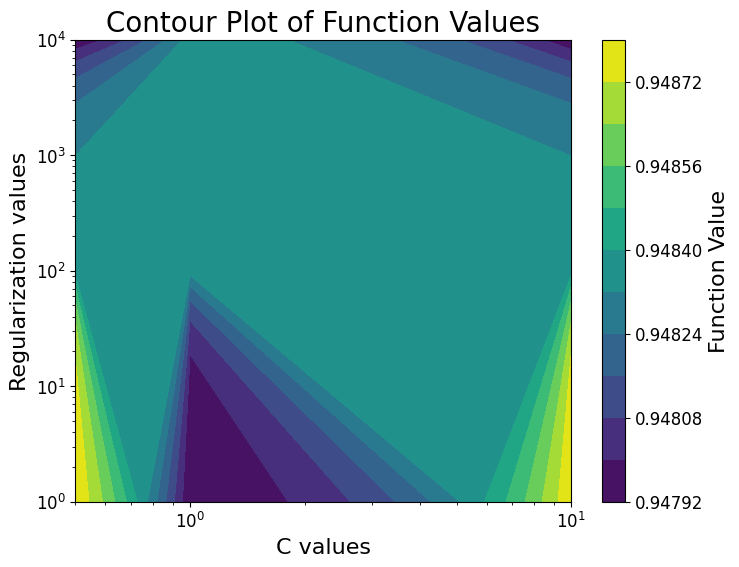

In [267]:
import numpy as np
import matplotlib.pyplot as plt

# Define the matrix
Z = train_scores  # Matrix values

# Define the corresponding axis values
C_values = np.array([0.5, 1, 10])  # Row dimension
Regul_values = np.array([1, 100, 10000])  # Column dimension

# Create a meshgrid for plotting
C_mesh, Regul_mesh = np.meshgrid(C_values, Regul_values, indexing="ij")  # Match matrix shape

# Create the contour plot
plt.figure(figsize=(8, 6))
contour = plt.contourf(C_mesh, Regul_mesh, Z, levels=10, cmap="viridis")  # Filled contours
plt.colorbar(contour, label="Function Value")

# Labels and formatting
plt.xscale("log")  # Log scale for better visualization
plt.yscale("log")  # Log scale for better visualization
plt.xlabel("C values")
plt.ylabel("Regularization values")
plt.title("Contour Plot of Function Values")

plt.show()


<a name="task-3"></a>

# Task 3: Regression with the Multi-Layer Perceptron [(index)](#index-task-3)

<a name="task-31"></a>

## (3.1) [(index)](#index-task-31)

In [268]:
def dense(X, W, b):
    """Full-connected MLP layer.

    Parameters:
        X (np.ndarray): K x h_in array of inputs, where K is the batch size and h_in is the input dimension.
        W (np.ndarray): h_out x h_in array for weights matrix parameters, where h_out is the output dimension.
        b (np.ndarray): Length h_out 1-D array for bias parameters

    Returns:
        a (np.ndarray): K x h_out array of pre-activations
    """
    a = np.vstack([W @ x + b for x in X]) ## <-- SOLUTION
    return a

In [269]:
## EDIT THIS FUNCTION
def relu_activation(a):
    """ReLU activation function.

    Parameters:
        a: K x h_out array of pre-activations

    Returns:
        h: K x h_out array of post-activations
    """
    # compute post-activations
    h = np.maximum(a, 0.)  ## <-- SOLUTION
    return h

## EDIT THIS FUNCTION
def grad_relu_activation(a):
    """Gradient of ReLU activation function.

    Parameters:
        a: K x h_out array of pre-activations

    Returns:
        grad: K x h_out gradient array of post-activations
    """
    # compute gradient
    grad = np.zeros_like(a) ## <-- SOLUTION
    grad[a>0] = 1 ## <-- SOLUTION
    return grad

In [270]:
# A lookup table for activation functions by their names.
activation_table = {
    "relu": relu_activation,
    "identity": lambda x: x
}

# A lookup table for gradient of activation functions by their names.
grad_activation_table = {
    "relu": grad_relu_activation,
    "identity": lambda x: np.ones_like(x)
}

class MLP:
    """
    This class represents a Multi-Layer Perceptron (MLP), that we are going
    to use to encapsulate two components:
        1. layers: the sequence of layers, where each layer is stored in
            a dictionary in the format {"W": np.ndarray, "b": np.ndarray},
            where "W" points to the weights array, and "b" points to
            the bias vector.
        2. rng: a pseudo random number generator (RNG) initialised to generate
            the random weights in a reproducible manner between different
            runtime sessions.
    This class is also shipped with methods that perform essential operations
    with a MLP, including:
        - add_layers: which creates a new layer with specified dimensions.
        - predict: applies the MLP forward pass to make predictions and produces
            a computational graph for the forward pass that can be used to
            compute gradients using backpropagation algorithm.
        in addition to other light functions that return simple statistics about
        the MLP.
    """
    def __init__(self, seed=42):
        self.layers = []
        self.rng = np.random.default_rng(seed)

    def n_parameters(self):
        """Return the total number of parameters of weights and biases."""
        return sum(l["b"].size + l["W"].size for l in self.layers)

    def n_layers(self):
        """Return current number of MLP layers (including input and output)."""
        return len(self.layers) + 1 if len(self.layers) > 0 else 0

    def layer_dim(self, index):
        """Retrieve the dimensions of the MLP layer at `index`."""
        return self.layers[index]["W"].shape

    def add_layer(self, in_dim, out_dim, activation="identity"):
        """Add fully connected layer to MLP.

        Parameters:
            in_dim (int): The input dimension of the layer.
            out_dim (int): The output dimension of the layer.
            activation (str): The activation function name.
        """
        # check if input-dimension matches output-dimension of previous layer
        if self.n_layers() > 0:
            last_out_dim, _ = self.layer_dim(-1)
            assert in_dim == last_out_dim, f"Input-dimension {in_dim} does not match output-dimension {last_out_dim} of previous layer."

        # the first layer, in our convention illustrated, does not apply activation on the input features X.
        if self.n_layers() == 0:
            assert activation == "identity", "Should not apply activations on the input features X, use Identity function for the first layer."


        # store each layer as a dictionary in the list, as shown in the
        # attached diagram.
        self.layers.append({
            # only for debugging.
            "index": len(self.layers),
            # apply Glorot initialisation for weights.
            # hint: use self.rng.normal()
            "W": self.rng.normal(size=(out_dim, in_dim)) * np.sqrt(2. / (in_dim + out_dim)), ## <-- SOLUTION
            # initialise bias vector with zeros.
            "b": np.zeros(out_dim), ## <-- SOLUTION
            # store the activation function (as string)
            "activation": activation
        })

    def predict(self, X):
        """Apply the forward pass on the input X and produce prediction and the
        forward computation graph.

        Parameters:
            X (np.ndarray): Feature matrix.

        Returns:
            (np.ndarray, List[Dict[str, np.ndarray]]): A tuple of the
            predictions and the computation graph as a sequence of intermediate
            values through the MLP, specifically each layer will have a corresponding
            intermediate values {"a": np.ndarray, "h": np.ndarray}, as shown in the
            attached diagram above.
        """
        # We assume that we work with a batch of examples (ndim==2).
        if X.ndim == 1:
            # If one example passed, add a dummy dimension for the batch.
            X = X.reshape(1, -1)

        # store pre- and post-activations in list
        forward_pass = [{"index": 0, "a": X, "h": X}]

        # iterate through hidden layers
        for k in range(1, len(self.layers)):
            # compute pre-activations
            a = dense(forward_pass[k - 1]["h"], self.layers[k - 1]["W"], self.layers[k - 1]["b"]) ## <-- SOLUTION
            activation = activation_table[self.layers[k]["activation"]] ## <-- SOLUTION
            forward_pass.append({"index": k, "a" : a, "h" : activation(a)})

        y_hat = dense(forward_pass[-1]["h"], self.layers[-1]["W"], self.layers[-1]["b"]) ## <-- SOLUTION
        # predicted target is output of last layer
        return y_hat, forward_pass

In [271]:
def mse_loss(y_true, y_pred):
    """Compute MSE-loss

    Parameters:
        y_true: ground-truth array, with shape (K, )
        y_pred: predictions array, with shape (K, )

    Returns:
        loss (float): MSE-loss
    """
    assert y_true.size == y_pred.size, "Ground-truth and predictions have different dimensions."

    # Adjustment to avoid subtraction between (K,) and (1, K) arrays.
    y_true = y_true.reshape(y_pred.shape)

    # Compute MSE loss
    loss = np.mean((y_true - y_pred)**2, keepdims=True) ## <-- SOLUTION
    return loss

In [272]:
def compound_loss(T, T_pred, l=0):

    assert T.size == T_pred.size, "Error"

    T = T.reshape(T_pred.shape)

    T_min, T_max = T[:,0], T[:,1]
    T_min_pred, T_max_pred = T_pred[:,0], T_pred[:,1]

    T_min = T_min.reshape(T_min_pred.shape)
    T_max = T_max.reshape(T_max_pred.shape)

    MSE_min = mse_loss(T_min, T_min_pred)
    MSE_max = mse_loss(T_max, T_max_pred)

    key = [T_min_pred > T_max_pred]

    return MSE_min + MSE_max + l*np.mean(key)


def compound_grad(T, T_pred, l=0):
    assert T.shape == T_pred.shape, "Error: Shapes of T and T_pred must match!"

    T_min, T_max = T[:, 0], T[:, 1]
    T_min_pred, T_max_pred = T_pred[:, 0], T_pred[:, 1]

    N = T_min.size

    grad_min = (2.0 * (-T_min + T_min_pred) / N).reshape(-1, 1)
    grad_max = (2.0 * (-T_max + T_max_pred) / N).reshape(-1, 1)

    key = (T_min_pred > T_max_pred).astype(float).reshape(-1, 1)

    grad_min += (l * key) / N
    grad_max -= (l * key) / N

    return np.hstack((grad_min, grad_max))

In [273]:
def backpropagate(layers, forward_pass, delta_output):
    """
    Apply the backpropagation algorithm to the MLP layers to compute the gradients starting from
    the output layer to the input layer, and starting the chain rule from the
    partial derivative of the loss function w.r.t the predictions $\hat{y}$

    Parameters:
        layers (List[Dict[str, np.ndarray]]): The MLP sequence of layers, as shown in the diagrams.
        forward_pass (List[Dict[str, np.ndarray]]): The forward pass intermediate values for
            each layer, representing a computation graph.
        delta_output (np.ndarray): the partial derivative of the loss function w.r.t the
            predictions $\hat{y}$, has the shape (K, 1), where K is the batch size.
    Returns:
        gradients (List[Dict[str, np.ndarray]]): The computed gradient using a structure symmetric in the layers, as shown
            in the diagrams.

    """
    # Create a list that will contain the gradients of all the layers.
    gradients = []

    # Initialise delta.
    delta = delta_output

    assert len(layers) == len(forward_pass), "Number of layers is expected to match the number of forward pass layers"

    # Iterate on layers backwardly, from output to input.
    # Calculate gradients w.r.t. weights and biases of each level and store in list of dictionaries.
    for layer, forward_computes in reversed(list(zip(layers, forward_pass))):   # zip iterates through pairs of layers and forward_pass
        assert forward_computes["index"] == layer["index"], "Mismatch in the index."

        h = forward_computes["h"]
        assert delta.shape[0] == h.shape[0], "Mismatch in the batch dimension."

        # Gradients are average gradients over batch
        gradients.append({"W" : (delta.T @ h) / h.shape[0], # <-- SOLUTION
                          "b" : delta.mean(axis=0)}) # <-- SOLUTION

        # Update the delta for the next iteration
        grad_activation_f = grad_activation_table[layer["activation"]]
        grad_activation = grad_activation_f(forward_computes["a"])

        # Calculate the delta for the backward layer.
        delta = np.stack([np.diag(gi) @ layer["W"].T @ di
                           for (gi, di) in zip(grad_activation, delta)]) # <-- SOLUTION.


    # Return now ordered list matching the layers.
    gradients = list(reversed(gradients))
    return gradients

<>:2: SyntaxWarning: invalid escape sequence '\h'
<>:2: SyntaxWarning: invalid escape sequence '\h'
C:\Users\User\AppData\Local\Temp\ipykernel_7560\3984133441.py:2: SyntaxWarning: invalid escape sequence '\h'
  """


In [274]:
def sgd_step(X, y, mlp, lam=0, learning_rate = 1e-3):
    """
    Apply a stochastic gradient descent step using the sampled batch.
    Parameters:
        X (np.ndarray): The input features array batch, with dimension (K, p).
        y (np.ndarray): The ground-truth of the batch, with dimension (K, 1).
        learning_rate (float): The learning rate multiplier for the update steps in SGD.
    Returns:
        updated_layers (List[Dict[str, np.ndarray]]): The updated layers after applying SGD.
    """
    # Compute the forward pass.
    y_hat, forward_pass = mlp.predict(X) ## <-- SOLUTION.

    # Compute the partial derivative of the loss w.r.t. to predictions `y_hat`.
    delta_output = compound_grad(y, y_hat, lam) ## <-- SOLUTION

    # Apply backpropagation algorithm to compute the gradients of the MLP parameters.
    gradients = backpropagate(mlp.layers, forward_pass, delta_output)  ## <-- SOLUTION.

    # mlp.layers and gradients are symmetric, as shown in the figure.
    updated_layers = []
    for layer, grad in zip(mlp.layers, gradients):
        W = layer["W"] - learning_rate * grad["W"] ## <-- SOLUTION.
        b = layer["b"] - learning_rate * grad["b"] ## <-- SOLUTION.
        updated_layers.append({"W": W, "b": b,
                               # keep the activation function.
                               "activation": layer["activation"],
                               # We use the index for asserts and debugging purposes only.
                               "index": layer["index"]})
    return updated_layers

def r2_score(y, y_hat):
    """R^2 score to assess regression performance."""

    # Adjustment to avoid subtraction between (K,) and (1, K) arrays.
    y = y.reshape(y_hat.shape)
    y_bar = y.mean()

    ss_tot = ((y - y_bar)**2).sum()
    ss_res = ((y - y_hat)**2).sum()
    return 1 - (ss_res/ss_tot)

def sgd(X_train, y_train, X_test, y_test, mlp, lam=0, learning_rate = 1e-3,
        n_epochs=10, minibatchsize=1, seed=42):
    """
    Run the Stochastic Gradient Descent (SGD) algorithm to optimise the parameters of MLP model to fit it on
    the training data using MSE loss.

    Parameters:
        X_train (np.ndarray): The training data features, with shape (N^{training}, p).
        y_train (np.ndarray): The training data ground-truth, with shape (N^{training}, 1).
        X_test (np.ndarray): The testing data features, with shape (N^{test}, p).
        y_test (np.ndarray): The testing data ground-truth, with shape (N^{test}, 1).
        mlp (MLP): The MLP object enacpsulating the MLP model.
        learning_rate (float): The learning_rate multiplier used in updating the parameters at each iteration.
        n_epochs (int): The number of training cycles that each covers the entire training examples.
        minibatchsize (int): The batch size used in each SGD step.
        seed (int): A seed for the RNG to ensure reproducibility across runtime sessions.

    Returns:
        mlp (MLP): MLP object encapuslating the trained MLP model.
        losses_train (np.ndarray): Train losses over epochs.
        losses_tset (np.ndarray): Test losses over epochs.
    """

    # get random number generator
    rng = np.random.default_rng(seed)

    # compute number of iterations per epoch
    n_iterations = int(len(y_train) / minibatchsize)

    # store losses
    losses_train = []
    losses_test = []

    epochs_bar = tqdm(range(n_epochs), desc="Epochs")

    for i in epochs_bar:

        # shuffle data
        p = rng.permutation(len(y_train))
        X_train_shuffled = X_train[p]
        y_train_shuffled = y_train[p]

        for j in range(n_iterations):
            # get batch
            X_batch = X_train_shuffled[j*minibatchsize : (j+1)*minibatchsize]
            y_batch = y_train_shuffled[j*minibatchsize : (j+1)*minibatchsize]

            # apply sgd step
            updated_layers = sgd_step(X_batch, y_batch, mlp, lam, learning_rate) ## <-- SOLUTION.

            # update weights and biases of MLP
            mlp.layers = updated_layers ## <-- SOLUTION.

        # compute loss at the end of each epoch
        y_hat_train, _ = mlp.predict(X_train)
        losses_train.append(compound_loss(y_train, y_hat_train, l=lam).squeeze())
        y_hat_test, _ = mlp.predict(X_test)
        losses_test.append(compound_loss(y_test, y_hat_test, l=lam).squeeze())
        epochs_bar.set_description(f'train_loss: {losses_train[-1]:.2f}, '
                                   f'test_loss: {losses_test[-1]:.2f}, '
                                   f'train_R^2: {r2_score(y_train, y_hat_train):.2f} '
                                   f'test_R^2: {r2_score(y_test, y_hat_test):.2f} ')
    return mlp, losses_train, losses_test


In [275]:
runway_train = np.array(airfield_stats_train.iloc[:, 7:9].values)
runway_test = np.array(airfield_stats_test.iloc[:, 7:9].values)

In [276]:
# compile architecture of MLP
mlp = MLP(seed=2)
mlp.add_layer(X_train.shape[1], 20)     ## <-- SOLUTION.    
mlp.add_layer(20, 20, "relu")      
mlp.add_layer(20, 2, "relu")             ## <-- SOLUTION.
print("Number of layers (including input and output layer):",mlp.n_layers())
print("Number of trainable parameters:",mlp.n_parameters())

# train MLP using SGD
mlp, losses_train, losses_test = sgd(X_train, runway_train, X_test, runway_test,
                                     mlp, lam=1, learning_rate = 5e-5,
                                     n_epochs=200,
                                     minibatchsize=20)                  ## <-- SOLUTION.

Number of layers (including input and output layer): 4
Number of trainable parameters: 602


train_loss: 16.50, test_loss: 19.04, train_R^2: 0.81 test_R^2: 0.76 : 100%|██████████| 200/200 [00:04<00:00, 41.09it/s] 


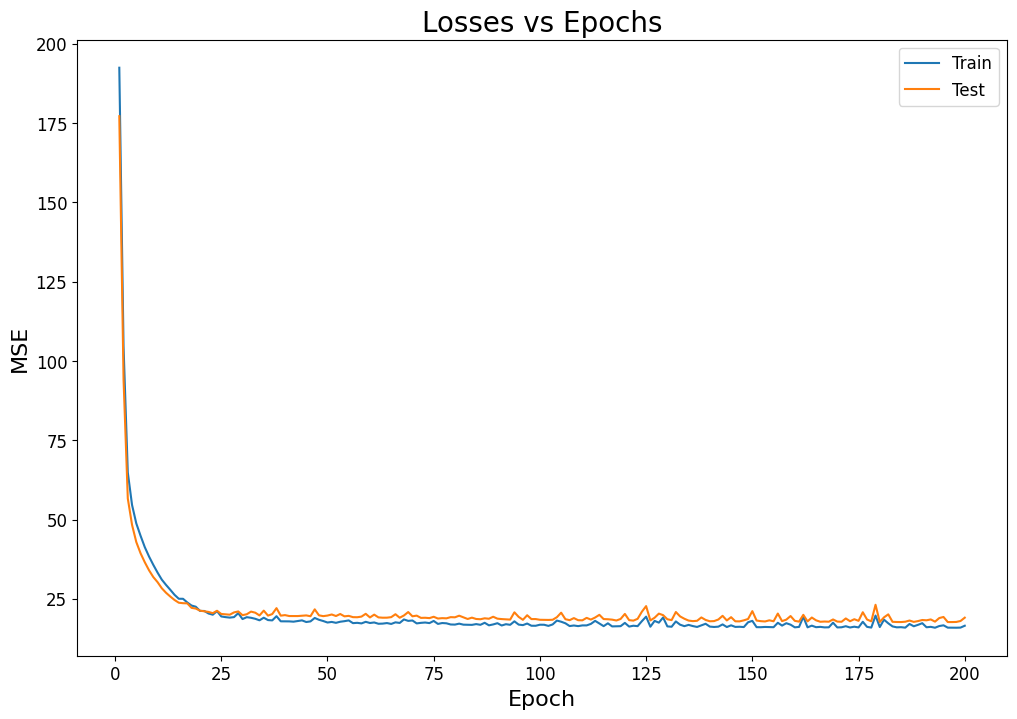

In [277]:
# plot training progress
fig, ax = plt.subplots(figsize=(12, 8))
ax.plot(np.arange(1,201),losses_train, label="Train")
ax.plot(np.arange(1,201),losses_test, label="Test")
ax.set(title="Losses vs Epochs", xlabel = "Epoch", ylabel = "MSE")
ax.legend()
plt.show()

Lambda = 0
  Number of layers (including input and output): 4
  Number of trainable parameters: 602


train_loss: 16.50, test_loss: 19.04, train_R^2: 0.81 test_R^2: 0.76 : 100%|██████████| 200/200 [00:05<00:00, 38.46it/s]


Lambda = 100
  Number of layers (including input and output): 4
  Number of trainable parameters: 602


train_loss: 17.35, test_loss: 19.21, train_R^2: 0.80 test_R^2: 0.76 : 100%|██████████| 200/200 [00:05<00:00, 39.87it/s]  


Lambda = 500
  Number of layers (including input and output): 4
  Number of trainable parameters: 602


train_loss: 324.80, test_loss: 307.13, train_R^2: -2.76 test_R^2: -2.91 : 100%|██████████| 200/200 [00:05<00:00, 39.08it/s]


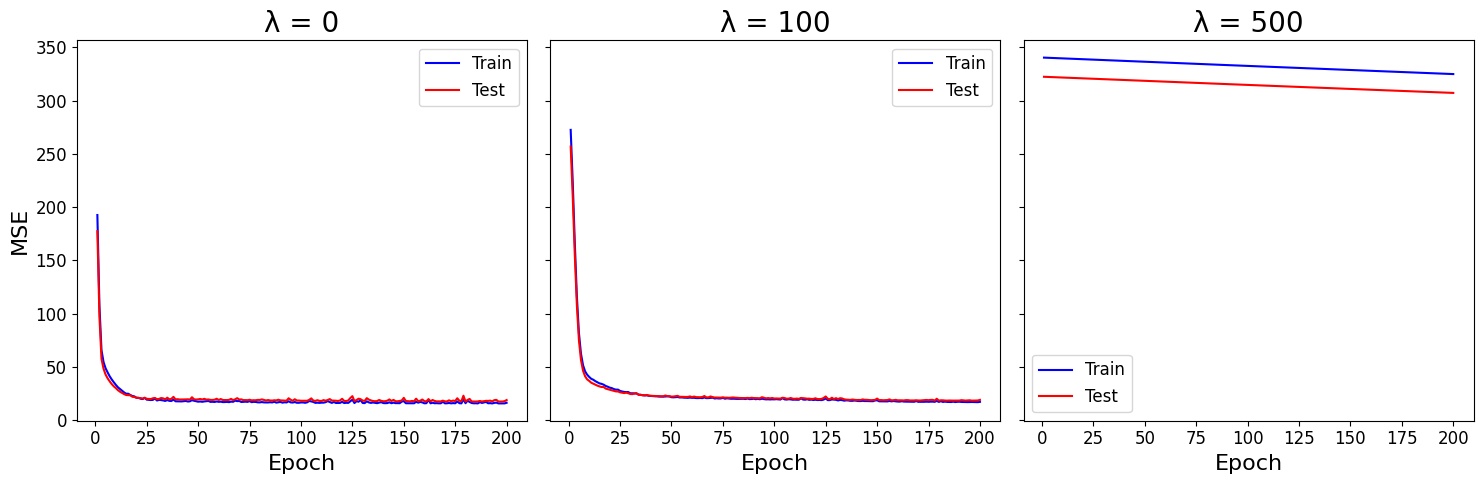

In [293]:
import numpy as np
import matplotlib.pyplot as plt

# List of lambda values to iterate over
lam_values = [0,100,500]
n_epochs = 200
epochs = np.arange(1, n_epochs + 1)

# Create a subplot for each lambda value
fig, axes = plt.subplots(
    1, len(lam_values), figsize=(5 * len(lam_values), 5), sharey=True
)

for i, lam in enumerate(lam_values):
    # Compile architecture of MLP for current lambda
    mlp = MLP(seed=2)
    mlp.add_layer(X_train.shape[1], 20)  # Input to hidden layer
    mlp.add_layer(20, 20, "relu")  # Hidden layer with ReLU
    mlp.add_layer(20, 2, "relu")  # Output layer
    print(f"Lambda = {lam}")
    print("  Number of layers (including input and output):", mlp.n_layers())
    print("  Number of trainable parameters:", mlp.n_parameters())

    # Train MLP using SGD with the current lambda value
    mlp, losses_train, losses_test = sgd(
        X_train,
        runway_train,
        X_test,
        runway_test,
        mlp,
        lam=lam,
        learning_rate=5e-5,
        n_epochs=n_epochs,
        minibatchsize=20,
    )

    # Plot training and test loss curves for this lambda value
    ax = axes[i]
    ax.plot(epochs, losses_train, label="Train", color="blue")
    ax.plot(epochs, losses_test, label="Test", color="red")
    ax.set_title(f"λ = {lam}")
    ax.set_xlabel("Epoch")
    if i == 0:
        ax.set_ylabel("MSE")
    ax.legend()

plt.tight_layout()
plt.show()

<a name="task-32"></a>

## (3.2) [(index)](#index-task-32)

In [ ]:
# we first import packages and libraries needed
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from collections import defaultdict
from tqdm import tqdm


# We set a global configuration for matplotlib to obtain well-readable plots
SMALL_SIZE = 12
MEDIUM_SIZE = 16
BIGGER_SIZE = 20

plt.rc("font", size=SMALL_SIZE)  # controls default text sizes
plt.rc("axes", titlesize=BIGGER_SIZE)  # fontsize of the axes title
plt.rc("axes", labelsize=MEDIUM_SIZE)  # fontsize of the x and y labels
plt.rc("xtick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("ytick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("legend", fontsize=SMALL_SIZE)  # legend fontsize
plt.rc("figure", titlesize=BIGGER_SIZE)  # fontsize of the figure title

# fixing random generator for reproducibility
rng = np.random.default_rng(0)
airfield_stats_test = pd.read_csv("airfield_statistics_test.csv")
airfield_stats_train = pd.read_csv("airfield_statistics_train.csv")

X_train_origin = airfield_stats_train.iloc[:, :6].values
y_train_origin = airfield_stats_train.iloc[:, 6].values

X_train = X_train_origin.copy()
y_train = y_train_origin.copy()

X_test_origin = airfield_stats_test.iloc[:, :6].values
y_test_origin = airfield_stats_test.iloc[:, 6].values

X_test = X_test_origin.copy()
y_test = y_test_origin.copy()

cat_columns_dict = {i: False for i in range(X_train.shape[1])}

feature_names = airfield_stats_train.columns[:6].tolist()


def dense(X, W, b):
    """Full-connected MLP layer.

    Parameters:
        X (np.ndarray): K x h_in array of inputs, where K is the batch size and h_in is the input dimension.
        W (np.ndarray): h_out x h_in array for weights matrix parameters, where h_out is the output dimension.
        b (np.ndarray): Length h_out 1-D array for bias parameters

    Returns:
        a (np.ndarray): K x h_out array of pre-activations
    """
    a = np.vstack([W @ x + b for x in X])  ## <-- SOLUTION
    return a


## EDIT THIS FUNCTION
def relu_activation(a):
    """ReLU activation function.

    Parameters:
        a: K x h_out array of pre-activations

    Returns:
        h: K x h_out array of post-activations
    """
    # compute post-activations
    h = np.maximum(a, 0.0)  ## <-- SOLUTION
    return h


## EDIT THIS FUNCTION
def grad_relu_activation(a):
    """Gradient of ReLU activation function.

    Parameters:
        a: K x h_out array of pre-activations

    Returns:
        grad: K x h_out gradient array of post-activations
    """
    # compute gradient
    grad = np.zeros_like(a)  ## <-- SOLUTION
    grad[a > 0] = 1  ## <-- SOLUTION
    return grad


import numpy as np


def random_boolean_array(n, m):

    arr = np.array([False] * n + [True] * (m - n))
    np.random.shuffle(arr)
    return arr


n, m = 5, 10
random_array = random_boolean_array(n, m)
print(random_array)
# A lookup table for activation functions by their names.
activation_table = {"relu": relu_activation, "identity": lambda x: x}

# A lookup table for gradient of activation functions by their names.
grad_activation_table = {
    "relu": grad_relu_activation,
    "identity": lambda x: np.ones_like(x),
}


class MLP:
    """
    This class represents a Multi-Layer Perceptron (MLP), that we are going
    to use to encapsulate two components:
        1. layers: the sequence of layers, where each layer is stored in
            a dictionary in the format {"W": np.ndarray, "b": np.ndarray},
            where "W" points to the weights array, and "b" points to
            the bias vector.
        2. rng: a pseudo random number generator (RNG) initialised to generate
            the random weights in a reproducible manner between different
            runtime sessions.
    This class is also shipped with methods that perform essential operations
    with a MLP, including:
        - add_layers: which creates a new layer with specified dimensions.
        - predict: applies the MLP forward pass to make predictions and produces
            a computational graph for the forward pass that can be used to
            compute gradients using backpropagation algorithm.
        in addition to other light functions that return simple statistics about
        the MLP.
    """

    def __init__(self, seed=42):
        self.layers = []
        self.rng = np.random.default_rng(seed)

    def n_parameters(self):
        """Return the total number of parameters of weights and biases."""
        return sum(l["b"].size + l["W"].size for l in self.layers)

    def n_layers(self):
        """Return current number of MLP layers (including input and output)."""
        return len(self.layers) + 1 if len(self.layers) > 0 else 0

    def layer_dim(self, index):
        """Retrieve the dimensions of the MLP layer at `index`."""
        return self.layers[index]["W"].shape

    def add_layer(self, in_dim, out_dim, activation="identity"):
        """Add fully connected layer to MLP.

        Parameters:
            in_dim (int): The input dimension of the layer.
            out_dim (int): The output dimension of the layer.
            activation (str): The activation function name.
        """
        # check if input-dimension matches output-dimension of previous layer
        if self.n_layers() > 0:
            last_out_dim, _ = self.layer_dim(-1)
            assert (
                in_dim == last_out_dim
            ), f"Input-dimension {in_dim} does not match output-dimension {last_out_dim} of previous layer."

        # the first layer, in our convention illustrated, does not apply activation on the input features X.
        if self.n_layers() == 0:
            assert (
                activation == "identity"
            ), "Should not apply activations on the input features X, use Identity function for the first layer."

        # store each layer as a dictionary in the list, as shown in the
        # attached diagram.
        self.layers.append(
            {
                # only for debugging.
                "index": len(self.layers),
                # apply Glorot initialisation for weights.
                # hint: use self.rng.normal()
                "W": self.rng.normal(size=(out_dim, in_dim))
                * np.sqrt(2.0 / (in_dim + out_dim)),  ## <-- SOLUTION
                # initialise bias vector with zeros.
                "b": np.zeros(out_dim),  ## <-- SOLUTION
                # store the activation function (as string)
                "activation": activation,
            }
        )

    def add_layer_dropout(self, in_dim, out_dim, dropout_value, activation="identity"):
        """Add fully connected layer to MLP.

        Parameters:
            in_dim (int): The input dimension of the layer.
            out_dim (int): The output dimension of the layer.
            activation (str): The activation function name.
        """
        # check if input-dimension matches output-dimension of previous layer
        if self.n_layers() > 0:
            last_out_dim, _ = self.layer_dim(-1)
            assert (
                in_dim == last_out_dim
            ), f"Input-dimension {in_dim} does not match output-dimension {last_out_dim} of previous layer."

        real_layer = random_boolean_array(int(in_dim * (1 - dropout_value)), in_dim)

        W_origin = self.rng.normal(size=(out_dim, in_dim)) * np.sqrt(
            2.0 / (in_dim + out_dim)
        )
        for i in range(out_dim):
            W_origin[i, :] = W_origin[i, :] * real_layer

        # the first layer, in our convention illustrated, does not apply activation on the input features X.
        if self.n_layers() == 0:
            assert (
                activation == "identity"
            ), "Should not apply activations on the input features X, use Identity function for the first layer."

        # store each layer as a dictionary in the list, as shown in the
        # attached diagram.
        self.layers.append(
            {
                # only for debugging.
                "index": len(self.layers),
                # apply Glorot initialisation for weights.
                # hint: use self.rng.normal()
                "W": W_origin,  ## <-- SOLUTION
                # initialise bias vector with zeros.
                "b": np.zeros(out_dim),  ## <-- SOLUTION
                # store the activation function (as string)
                "activation": activation,
            }
        )

    def predict(self, X):
        """Apply the forward pass on the input X and produce prediction and the
        forward computation graph.

        Parameters:
            X (np.ndarray): Feature matrix.

        Returns:
            (np.ndarray, List[Dict[str, np.ndarray]]): A tuple of the
            predictions and the computation graph as a sequence of intermediate
            values through the MLP, specifically each layer will have a corresponding
            intermediate values {"a": np.ndarray, "h": np.ndarray}, as shown in the
            attached diagram above.
        """
        # We assume that we work with a batch of examples (ndim==2).
        if X.ndim == 1:
            # If one example passed, add a dummy dimension for the batch.
            X = X.reshape(1, -1)

        # store pre- and post-activations in list
        forward_pass = [{"index": 0, "a": X, "h": X}]

        # iterate through hidden layers
        for k in range(1, len(self.layers)):
            # compute pre-activations
            a = dense(
                forward_pass[k - 1]["h"],
                self.layers[k - 1]["W"],
                self.layers[k - 1]["b"],
            )  ## <-- SOLUTION
            activation = activation_table[self.layers[k]["activation"]]  ## <-- SOLUTION
            forward_pass.append({"index": k, "a": a, "h": activation(a)})

        y_hat = dense(
            forward_pass[-1]["h"], self.layers[-1]["W"], self.layers[-1]["b"]
        )  ## <-- SOLUTION
        # predicted target is output of last layer
        return y_hat, forward_pass


def mse_loss(y_true, y_pred):
    """Compute MSE-loss

    Parameters:
        y_true: ground-truth array, with shape (K, )
        y_pred: predictions array, with shape (K, )

    Returns:
        loss (float): MSE-loss
    """
    assert (
        y_true.size == y_pred.size
    ), "Ground-truth and predictions have different dimensions."

    # Adjustment to avoid subtraction between (K,) and (1, K) arrays.
    y_true = y_true.reshape(y_pred.shape)

    # Compute MSE loss
    loss = np.mean((y_true - y_pred) ** 2, keepdims=True)  ## <-- SOLUTION
    return loss


def compound_loss(T, T_pred, l=0):

    assert T.size == T_pred.size, "Error"

    T = T.reshape(T_pred.shape)

    T_min, T_max = T[:, 0], T[:, 1]
    T_min_pred, T_max_pred = T_pred[:, 0], T_pred[:, 1]

    T_min = T_min.reshape(T_min_pred.shape)
    T_max = T_max.reshape(T_max_pred.shape)

    MSE_min = mse_loss(T_min, T_min_pred)
    MSE_max = mse_loss(T_max, T_max_pred)

    key = [T_min_pred > T_max_pred]

    return MSE_min + MSE_max + l * np.mean(key)


def compound_grad(T, T_pred, l=0):
    assert T.shape == T_pred.shape, "Error: Shapes of T and T_pred must match!"

    T_min, T_max = T[:, 0], T[:, 1]
    T_min_pred, T_max_pred = T_pred[:, 0], T_pred[:, 1]

    N = T_min.size

    grad_min = (2.0 * (-T_min + T_min_pred) / N).reshape(-1, 1)
    grad_max = (2.0 * (-T_max + T_max_pred) / N).reshape(-1, 1)

    key = (T_min_pred > T_max_pred).astype(float).reshape(-1, 1)

    grad_min += (l * key) / N
    grad_max -= (l * key) / N

    return np.hstack((grad_min, grad_max))


def backpropagate(layers, forward_pass, delta_output):
    """
    Apply the backpropagation algorithm to the MLP layers to compute the gradients starting from
    the output layer to the input layer, and starting the chain rule from the
    partial derivative of the loss function w.r.t the predictions $\hat{y}$

    Parameters:
        layers (List[Dict[str, np.ndarray]]): The MLP sequence of layers, as shown in the diagrams.
        forward_pass (List[Dict[str, np.ndarray]]): The forward pass intermediate values for
            each layer, representing a computation graph.
        delta_output (np.ndarray): the partial derivative of the loss function w.r.t the
            predictions $\hat{y}$, has the shape (K, 1), where K is the batch size.
    Returns:
        gradients (List[Dict[str, np.ndarray]]): The computed gradient using a structure symmetric in the layers, as shown
            in the diagrams.

    """
    # Create a list that will contain the gradients of all the layers.
    gradients = []

    # Initialise delta.
    delta = delta_output

    assert len(layers) == len(
        forward_pass
    ), "Number of layers is expected to match the number of forward pass layers"

    # Iterate on layers backwardly, from output to input.
    # Calculate gradients w.r.t. weights and biases of each level and store in list of dictionaries.
    for layer, forward_computes in reversed(
        list(zip(layers, forward_pass))
    ):  # zip iterates through pairs of layers and forward_pass
        assert forward_computes["index"] == layer["index"], "Mismatch in the index."

        h = forward_computes["h"]
        assert delta.shape[0] == h.shape[0], "Mismatch in the batch dimension."

        # Gradients are average gradients over batch
        gradients.append(
            {"W": (delta.T @ h) / h.shape[0], "b": delta.mean(axis=0)}  # <-- SOLUTION
        )  # <-- SOLUTION

        # Update the delta for the next iteration
        grad_activation_f = grad_activation_table[layer["activation"]]
        grad_activation = grad_activation_f(forward_computes["a"])

        # Calculate the delta for the backward layer.
        delta = np.stack(
            [
                np.diag(gi) @ layer["W"].T @ di
                for (gi, di) in zip(grad_activation, delta)
            ]
        )  # <-- SOLUTION.

    # Return now ordered list matching the layers.
    gradients = list(reversed(gradients))
    return gradients


def sgd_step(X, y, mlp, lam=0, learning_rate=1e-3):
    """
    Apply a stochastic gradient descent step using the sampled batch.
    Parameters:
        X (np.ndarray): The input features array batch, with dimension (K, p).
        y (np.ndarray): The ground-truth of the batch, with dimension (K, 1).
        learning_rate (float): The learning rate multiplier for the update steps in SGD.
    Returns:
        updated_layers (List[Dict[str, np.ndarray]]): The updated layers after applying SGD.
    """
    # Compute the forward pass.
    y_hat, forward_pass = mlp.predict(X)  ## <-- SOLUTION.

    # Compute the partial derivative of the loss w.r.t. to predictions `y_hat`.
    delta_output = compound_grad(y, y_hat, lam)  ## <-- SOLUTION

    # Apply backpropagation algorithm to compute the gradients of the MLP parameters.
    gradients = backpropagate(mlp.layers, forward_pass, delta_output)  ## <-- SOLUTION.

    # mlp.layers and gradients are symmetric, as shown in the figure.
    updated_layers = []
    for layer, grad in zip(mlp.layers, gradients):
        W = layer["W"] - learning_rate * grad["W"]  ## <-- SOLUTION.
        b = layer["b"] - learning_rate * grad["b"]  ## <-- SOLUTION.
        updated_layers.append(
            {
                "W": W,
                "b": b,
                # keep the activation function.
                "activation": layer["activation"],
                # We use the index for asserts and debugging purposes only.
                "index": layer["index"],
            }
        )
    return updated_layers


def r2_score(y, y_hat):
    """R^2 score to assess regression performance."""

    # Adjustment to avoid subtraction between (K,) and (1, K) arrays.
    y = y.reshape(y_hat.shape)
    y_bar = y.mean()

    ss_tot = ((y - y_bar) ** 2).sum()
    ss_res = ((y - y_hat) ** 2).sum()
    return 1 - (ss_res / ss_tot)


def sgd(
    X_train,
    y_train,
    X_test,
    y_test,
    mlp,
    lam=0,
    learning_rate=1e-3,
    n_epochs=10,
    minibatchsize=1,
    seed=42,
):
    """
    Run the Stochastic Gradient Descent (SGD) algorithm to optimise the parameters of MLP model to fit it on
    the training data using MSE loss.

    Parameters:
        X_train (np.ndarray): The training data features, with shape (N^{training}, p).
        y_train (np.ndarray): The training data ground-truth, with shape (N^{training}, 1).
        X_test (np.ndarray): The testing data features, with shape (N^{test}, p).
        y_test (np.ndarray): The testing data ground-truth, with shape (N^{test}, 1).
        mlp (MLP): The MLP object enacpsulating the MLP model.
        learning_rate (float): The learning_rate multiplier used in updating the parameters at each iteration.
        n_epochs (int): The number of training cycles that each covers the entire training examples.
        minibatchsize (int): The batch size used in each SGD step.
        seed (int): A seed for the RNG to ensure reproducibility across runtime sessions.

    Returns:
        mlp (MLP): MLP object encapuslating the trained MLP model.
        losses_train (np.ndarray): Train losses over epochs.
        losses_tset (np.ndarray): Test losses over epochs.
    """

    # get random number generator
    rng = np.random.default_rng(seed)

    # compute number of iterations per epoch
    n_iterations = int(len(y_train) / minibatchsize)

    # store losses
    losses_train = []
    losses_test = []

    epochs_bar = tqdm(range(n_epochs), desc="Epochs")

    for i in epochs_bar:

        # shuffle data
        p = rng.permutation(len(y_train))
        X_train_shuffled = X_train[p]
        y_train_shuffled = y_train[p]

        for j in range(n_iterations):
            # get batch
            X_batch = X_train_shuffled[j * minibatchsize : (j + 1) * minibatchsize]
            y_batch = y_train_shuffled[j * minibatchsize : (j + 1) * minibatchsize]

            # apply sgd step
            updated_layers = sgd_step(
                X_batch, y_batch, mlp, lam, learning_rate
            )  ## <-- SOLUTION.

            # update weights and biases of MLP
            mlp.layers = updated_layers  ## <-- SOLUTION.

        # compute loss at the end of each epoch
        y_hat_train, _ = mlp.predict(X_train)
        losses_train.append(compound_loss(y_train, y_hat_train, l=lam).squeeze())
        y_hat_test, _ = mlp.predict(X_test)
        losses_test.append(compound_loss(y_test, y_hat_test, l=lam).squeeze())
        epochs_bar.set_description(
            f"train_loss: {losses_train[-1]:.2f}, "
            f"test_loss: {losses_test[-1]:.2f}, "
            f"train_R^2: {r2_score(y_train, y_hat_train):.2f} "
            f"test_R^2: {r2_score(y_test, y_hat_test):.2f} "
        )
    return mlp, losses_train, losses_test


runway_train = np.array(airfield_stats_train.iloc[:, 7:9].values)
runway_test = np.array(airfield_stats_test.iloc[:, 7:9].values)
# compile architecture of MLP
mlp = MLP(seed=2)
mlp.add_layer(X_train.shape[1], 100)  ## <-- SOLUTION.
mlp.add_layer(100, 200, "relu")
mlp.add_layer(200, 300, "relu")
mlp.add_layer_dropout(300, 100, 0.1, "relu")
mlp.add_layer(100, 2, "relu")  ## <-- SOLUTION.
print("Number of layers (including input and output layer):", mlp.n_layers())
print("Number of trainable parameters:", mlp.n_parameters())

# train MLP using SGD
mlp, losses_train, losses_test = sgd(
    X_train,
    runway_train,
    X_test,
    runway_test,
    mlp,
    lam=0,
    learning_rate=5e-5,
    n_epochs=200,
    minibatchsize=16,
)  ## <-- SOLUTION.
# plot training progress
fig, ax = plt.subplots(figsize=(12, 8))
ax.plot(np.arange(1, 201), losses_train, label="Train")
ax.plot(np.arange(1, 201), losses_test, label="Test")
ax.set(title="Losses vs Epochs", xlabel="Epoch", ylabel="MSE")
ax.legend()
plt.show()
# compile architecture of MLP
mlp = MLP(seed=2)
mlp.add_layer(X_train.shape[1], 100)  ## <-- SOLUTION.
mlp.add_layer(100, 200, "relu")
mlp.add_layer(200, 300, "relu")
mlp.add_layer(300, 100, "relu")
mlp.add_layer(100, 2, "relu")  ## <-- SOLUTION.
print("Number of layers (including input and output layer):", mlp.n_layers())
print("Number of trainable parameters:", mlp.n_parameters())

# train MLP using SGD
mlp, losses_train, losses_test = sgd(
    X_train,
    runway_train,
    X_test,
    runway_test,
    mlp,
    lam=0,
    learning_rate=5e-5,
    n_epochs=200,
    minibatchsize=16,
)
# plot training progress
fig, ax = plt.subplots(figsize=(12, 8))
ax.plot(np.arange(1, 201), losses_train, label="Train")
ax.plot(np.arange(1, 201), losses_test, label="Test")
ax.set(title="Losses vs Epochs", xlabel="Epoch", ylabel="MSE")
ax.legend()
plt.show()